<p style="text-align:center"><img src="../images/04_10_spatial_capstone.png" alt="Spatial Statistics Capstone" width="100%"></p>


# Spatiotemporal Patterns, Hotspots, and Predictors of Crime Across NYC Police Precincts

This is Part 10 (Capstone) of the spatial-statistics module. It follows the course guideline *crime analysis.qmd* step by step: how crime varies across NYC precincts over time, which precincts are persistent or emerging hotspots, and whether violent and property crimes show different spatial and temporal dynamics.

All crime data come from the local **NYC Crime spatiotemporal database** built from GeoData@Columbia *New York City Crimes by Precinct* and the NYPD historical offense tables Columbia cites as the attribute source:

- `Data/00_shared/data_spatial_stat/NYC_Crime_data/nyc_crime_spatiotemporal.gpkg`
- `Data/00_shared/data_spatial_stat/NYC_Crime_data/nyc_crime.sqlite`

Geometry is NYPD precinct polygons (NAD83 / New York Long Island ftUS, EPSG:2263). Interactive maps use Leaflet with an OpenStreetMap basemap (WGS84).

Following the guideline's recommended design, the notebook concentrates on three outcomes - **robbery**, **burglary**, and **felony assault** - plus violent and property composites, and compares three modeling approaches: classical spatial statistics, count and spatial panel regression, and Bayesian spatial smoothing.

## Overview

> Across NYC police precincts from 2000 to 2025, which precincts have the highest crime counts and area rates, are high-crime precincts spatially clustered, how have patterns changed over time, which precincts are persistent or emerging hotspots, and do robbery, burglary, and felony assault share the same geography?

### Research objectives

| Objective | Research question |
|---|---|
| 1. Crime distribution | Which precincts have the highest crime counts and rates? |
| 2. Spatial clustering | Are high-crime precincts geographically clustered? |
| 3. Temporal trends | How have crime patterns changed over time? |
| 4. Spatiotemporal hotspots | Which precincts experience persistent or emerging crime hotspots? |
| 5. Crime determinants | How are lagged crime, neighboring crime, area exposure, and offense mix associated with crime levels? |

### Hypotheses

- H1: Crime exhibits significant spatial autocorrelation across NYC precincts.
- H2: Crime hotspots are persistent in some precincts but shift over time.
- H3: Violent and property crimes have different spatial and temporal patterns.
- H4: Crime rates exhibit long-term temporal trends (annual panel; monthly seasonality is out of scope here).
- H5: Lagged crime, neighboring crime, and other offense activity are associated with crime patterns (socioeconomic ACS covariates are noted as an extension).

### Outcomes

| Variable | Definition | Role |
|---|---|---|
| `robbery` | Robbery counts | Violent focus outcome |
| `burglery` | Burglary counts (Columbia field spelling) | Property focus outcome |
| `assault` | Felony assault counts | Violent focus outcome |
| `violent` | `murder + rape + robbery + assault` | Violent composite |
| `property` | `burglery + gdlarceny + gdlarcauto` | Property composite |
| `drug` | `feldrug + misdrug` | Enforcement-activity proxy in the panel models |
| `*_rate` | Count per km$^2$ of precinct area | Exposure-adjusted map / model target |
| `delta_*` | 2024 minus 2019 count | Recent change |

### Workflow (guideline section in brackets)

| Step | What we do |
|------|------------|
| Data [3, Steps 1-4] | Load GeoPackage panel + SQLite; CRS audit; boundary-vintage audit; harmonized 75-unit panel; composites, boroughs, area rates |
| Distribution [Step 5] | Choropleths of counts and rates for 2024; fixed-scale maps across years; Leaflet/OSM maps |
| Temporal [Step 6] | Citywide annual series; borough series; indexed trends by offense; Mann-Kendall tests; precinct-year heatmap; 2019 vs 2024 change |
| Autocorrelation [Step 7] | Global Moran's I by year and crime category; Queen, Rook, and KNN sensitivity |
| Local clusters [Step 8] | LISA (uncorrected and FDR) and Gi* for 2024 levels and the 2019-2024 change; overlap between outcomes |
| Space-time [Model 6] | Emerging hotspot categories from the Gi* time path for all three outcomes |
| Cross-section [Models 2-3] | Poisson / negative binomial; OLS, spatial lag, spatial error on 2024 area rates |
| Panel [Models 1, 2, 4] | Two-way fixed effects; Poisson / negative binomial with fixed effects; dynamic spatial lag panel |
| Bayesian [Model 5] | BYM relative-risk maps and exceedance probabilities for three five-year windows |
| Validation [6] | Forward (one-year-ahead) validation and leave-one-borough-out validation |
| Report | Decision log, caveats, extensions |

**Caveats.** Precinct counts are ecological. Reported crime is not identical to actual crime. Area rates are a proxy for exposure when residential population is unavailable; business and tourist precincts can look extreme under resident-population rates and under area rates for different reasons. Precinct **116** (created Dec 2024) has Excel counts in SQLite but no 2022 geometry in the spatial panel. Precinct **121** (Staten Island) opened in 2013, so full-period analyses use a harmonized geography that merges precincts 120, 121, and 122. The local database is annual, so seasonal analysis and monthly models from the guideline are not attempted.

## API overview

```
- geopandas / sqlite3 -> NYC Crime GeoPackage + SQLite
- Queen, Rook, KNN, W
- Moran, moran_scatter
- local_moran_clusters, getis_ord_gi
- OLS (lm_tests), SpatialLag, SpatialError, compare_models
- BYM, expected_counts (Bayesian disease-mapping module)
- statsmodels GLM (Poisson, NegativeBinomial) and OLS with clustered errors
- pymannkendall (trend tests)
- folium (Leaflet) + OpenStreetMap
- matplotlib / apply_map_style
```

## Setup

Locate the repository root, import helpers, and fix the random seed, permutation count, and analysis window.

**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README. It also uses `pymannkendall`, `statsmodels`, which no GeoLattice option installs: `pip install pymannkendall statsmodels`.

In [1]:
import sys
import warnings
import json
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm
from matplotlib.patches import Patch
from scipy import sparse
from IPython.display import Markdown, display
import folium
from branca.colormap import LinearColormap
import statsmodels.api as sm
import pymannkendall as mk

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "pyproject.toml").is_file() and (candidate / "Data").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "Data" / "00_shared" / "data_spatial_stat" / "NYC_Crime_data"
GPKG = DATA / "nyc_crime_spatiotemporal.gpkg"
DB = DATA / "nyc_crime.sqlite"

import geolattice.spatial_statistics
from geolattice.viz import apply_map_style
from geolattice.spatial_statistics.weights import Queen, Rook, KNN, W
from geolattice.spatial_statistics.esda import Moran
from geolattice.spatial_statistics.viz import moran_scatter
from geolattice.spatial_statistics.cluster import local_moran_clusters, getis_ord_gi
from geolattice.spatial_statistics.regression import OLS, SpatialLag, SpatialError, compare_models
from geolattice.spatial_statistics.bayes import BYM, expected_counts

apply_map_style()

SEED = 7
PERM = 999
PERM_LOCAL = 9999  # finer p-value grid for FDR-adjusted local statistics
ALPHA = 0.05
YEAR_BASE = 2019
YEAR_CUR = 2024
FT2_TO_KM2 = (0.304800609601219 ** 2) / 1e6
SI_MERGE = [120, 121, 122]  # precinct 121 opened in 2013 from parts of 120 and 122
SI_UNIT = 120               # id of the merged Staten Island unit in the harmonized panel
VAL_YEARS = list(range(2016, 2026))  # forward-validation target years
BYM_WINDOWS = {"2001-2005": (2001, 2005), "2011-2015": (2011, 2015), "2021-2025": (2021, 2025)}

FOCUS_COUNTS = {
    "robbery": "Robbery",
    "burglery": "Burglary",
    "assault": "Felony assault",
}
FOCUS_COLORS = {"robbery": "#b22222", "burglery": "#1f4e79", "assault": "#e67e22"}
COMPOSITES = {
    "violent": ["murder", "rape", "robbery", "assault"],
    "property": ["burglery", "gdlarceny", "gdlarcauto"],
}

print(f"geolattice.spatial_statistics : version {geolattice.spatial_statistics.__version__}")
print(f"gpkg : {GPKG.relative_to(ROOT)}  ({GPKG.stat().st_size / 1e6:.1f} MB)")
print(f"sqlite : {DB.relative_to(ROOT)}  ({DB.stat().st_size / 1e6:.1f} MB)")
print(f"seed {SEED}  |  permutations {PERM}  |  alpha {ALPHA}")
print(f"change window {YEAR_BASE}-{YEAR_CUR}")
print("focus outcomes:", ", ".join(FOCUS_COUNTS))


def borough_of(precinct: int) -> str:
    """NYPD precinct numbering: patrol boroughs occupy fixed number ranges."""
    p = int(precinct)
    if p <= 34:
        return "Manhattan"
    if p <= 52:
        return "Bronx"
    if p <= 94:
        return "Brooklyn"
    if p <= 115:
        return "Queens"
    return "Staten Island"


geolattice.spatial_statistics : version 0.3.49
gpkg : Data/00_shared/data_spatial_stat/NYC_Crime_data/nyc_crime_spatiotemporal.gpkg  (79.7 MB)
sqlite : Data/00_shared/data_spatial_stat/NYC_Crime_data/nyc_crime.sqlite  (27.7 MB)
seed 7  |  permutations 999  |  alpha 0.05
change window 2019-2024
focus outcomes: robbery, burglery, assault


## Data: download inspection and panel construction

The guideline starts from Columbia's Crimes by Precinct collection. Here the prepared GeoPackage layer `precinct_crime_annual_2000_2025` is already a precinct-year panel with Columbia-style offense fields. We inspect CRS, identifiers, temporal coverage, and build violent/property composites plus area-based rates.


In [2]:
layers = gpd.list_layers(GPKG)
display(layers)

panel = gpd.read_file(GPKG, layer="precinct_crime_annual_2000_2025").copy()
con = sqlite3.connect(DB)
catalog = pd.read_sql("SELECT * FROM dataset_catalog", con)
counts = pd.read_sql(
    "SELECT precinct, year, offense_code, category, count, source "
    "FROM crime_counts WHERE source = 'nypd_historical_excel'",
    con,
)
con.close()

panel["area_km2"] = panel.geometry.area * FT2_TO_KM2
panel["violent"] = panel[COMPOSITES["violent"]].sum(axis=1)
panel["property"] = panel[COMPOSITES["property"]].sum(axis=1)
panel["borough"] = panel["precinct"].map(borough_of)
for col in list(FOCUS_COUNTS) + ["violent", "property", "tot_7major"]:
    panel[f"{col}_rate"] = panel[col] / panel["area_km2"]

print("CRS:", panel.crs)
print(
    f"panel: {len(panel):,} rows | {panel['precinct'].nunique()} precincts | "
    f"years {int(panel['year'].min())}-{int(panel['year'].max())}"
)
display(catalog)
display(panel[["precinct", "year", "robbery", "burglery", "assault", "violent", "property", "area_km2"]].head())

assert str(panel.crs.to_epsg()) == "2263"
assert panel.geometry.is_valid.all()
display(Markdown(
    f"Loaded **{panel['precinct'].nunique()}** precincts x "
    f"**{panel['year'].nunique()}** years "
    f"({int(panel['year'].min())}-{int(panel['year'].max())}) in EPSG:2263. "
    f"SQLite long table has **{len(counts):,}** Excel-sourced offense rows. "
    f"Mean precinct area is **{panel.groupby('precinct')['area_km2'].first().mean():.1f} km$^2$**."
))


,name,geometry_type
0,columbia_precinct_crime_annual,MultiPolygon
1,precinct_crime_annual_2000_2025,MultiPolygon
2,precincts_2022,MultiPolygon


CRS: EPSG:2263
panel: 1,989 rows | 77 precincts | years 2000-2025


,dataset_id,dataset_name,description,source_url,years
0,1,columbia_geodata_wfs,GeoData@Columbia New York City Crimes by Preci...,https://geodata.library.columbia.edu/?q=Crimes...,2000-2022
1,2,nypd_historical_excel,NYPD historical felony/misdemeanor/violation c...,https://www.nyc.gov/site/nypd/stats/crime-stat...,2000-2025


,precinct,year,robbery,burglery,assault,violent,property,area_km2
0,1,2000,252,475,139,406,3032,4.393064
1,1,2001,188,437,164,358,2711,4.393064
2,1,2002,210,297,147,369,2346,4.393064
3,1,2003,164,403,134,311,2338,4.393064
4,1,2004,154,246,129,296,2087,4.393064


Loaded **77** precincts x **26** years (2000-2025) in EPSG:2263. SQLite long table has **67,694** Excel-sourced offense rows. Mean precinct area is **10.2 km$^2$**.

### Harmonize precinct boundaries

The guideline's Step 2 asks whether precinct boundaries and identifiers changed over the study period. The Columbia catalog layer stores each year with its own polygons, so it can be used to audit the geography behind the 2000-2025 panel, which joins every year to 2022 polygons. Counts for a precinct whose territory changed are not comparable over time unless the geography is harmonized.

In [3]:
# 1) Which precincts exist in each yearly vintage, and did their polygons change?
col = gpd.read_file(GPKG, layer="columbia_precinct_crime_annual")
col["area_km2"] = col.geometry.area * FT2_TO_KM2
n_by_year = col.groupby("year")["precinct"].nunique()
area_w = col.pivot_table(index="precinct", columns="year", values="area_km2")
y0, y1 = int(area_w.columns.min()), int(area_w.columns.max())
vint = pd.DataFrame({f"area_{y0}": area_w[y0], f"area_{y1}": area_w[y1]})
vint["pct_change"] = 100 * (vint[f"area_{y1}"] / vint[f"area_{y0}"] - 1)
changed = vint[(vint["pct_change"].abs() > 1) | vint[f"area_{y0}"].isna()].sort_values("pct_change")
break_years = [int(y) for y in n_by_year.index[n_by_year.diff().fillna(0) != 0]]
print("precincts per year in the Columbia layer:", n_by_year.groupby(n_by_year).agg(lambda s: f"{s.index.min()}-{s.index.max()}").to_dict())
display(Markdown(f"**Precincts whose area differs by more than 1% between the {y0} and {y1} polygons**"))
display(changed.style.format("{:.2f}", na_rep="not yet created"))

# 2) Do the two sources agree where they overlap?
both = col.merge(
    panel[["precinct", "year", *FOCUS_COUNTS]], on=["precinct", "year"], suffixes=("_wfs", "_xls")
)
agree = {c: float((both[f"{c}_wfs"] == both[f"{c}_xls"]).mean()) for c in FOCUS_COUNTS}
print("share of precinct-years where Columbia WFS and NYPD Excel counts are identical:", agree)

# 3) Harmonized geography: merge the Staten Island precincts affected by the 2013 split
count_cols = [
    c for c in panel.select_dtypes("number").columns
    if c not in ("precinct", "year", "area_km2") and not c.endswith("_rate")
]
tab = pd.DataFrame(panel.drop(columns="geometry"))
tab["unit"] = tab["precinct"].replace({p: SI_UNIT for p in SI_MERGE})
tab_h = tab.groupby(["unit", "year"], as_index=False)[count_cols].sum()

geom_h = panel.loc[panel["year"] == panel["year"].max(), ["precinct", "geometry"]].copy()
geom_h["unit"] = geom_h["precinct"].replace({p: SI_UNIT for p in SI_MERGE})
geom_h = geom_h.dissolve(by="unit")[["geometry"]].sort_index()
geom_h["area_km2"] = geom_h.geometry.area * FT2_TO_KM2
geom_h["borough"] = [borough_of(u) for u in geom_h.index]

panel_h = gpd.GeoDataFrame(
    tab_h.merge(geom_h.reset_index(), on="unit").rename(columns={"unit": "precinct"}),
    geometry="geometry", crs=panel.crs,
).sort_values(["precinct", "year"]).reset_index(drop=True)
panel_h["drug"] = panel_h["feldrug"] + panel_h["misdrug"]
for c in list(FOCUS_COUNTS) + ["violent", "property", "tot_7major"]:
    panel_h[f"{c}_rate"] = panel_h[c] / panel_h["area_km2"]

units = list(geom_h.index)
years = sorted(int(v) for v in panel_h["year"].unique())
N_U, N_T = len(units), len(years)
assert len(panel_h) == N_U * N_T, "harmonized panel is not balanced"


def mat(column: str, frame: pd.DataFrame = None) -> np.ndarray:
    # Harmonized panel as a (units x years) matrix, rows in `units` order.
    frame = panel_h if frame is None else frame
    return (
        frame.pivot(index="precinct", columns="year", values=column)
        .reindex(index=units, columns=years).to_numpy(float)
    )


raw_rows = panel.groupby("precinct")["year"].nunique()
display(Markdown(
    f"The Columbia layer has **{int(n_by_year.min())}** precincts until **{break_years[0] - 1}** and "
    f"**{int(n_by_year.max())}** from **{break_years[0]}**, when precinct 121 was created from parts of 120 and 122. "
    f"In the 2000-2025 panel **{int((raw_rows < panel['year'].nunique()).sum())}** precinct has an incomplete series, "
    f"and the pre-{break_years[0]} counts of precincts 120 and 122 refer to larger territories than their 2022 polygons. "
    f"Merging {', '.join(str(p) for p in SI_MERGE)} gives a balanced panel of **{N_U}** units x **{N_T}** years "
    f"(**{len(panel_h):,}** rows). Other boundary revisions are smaller (at most "
    f"**{changed.drop(index=[p for p in SI_MERGE if p in changed.index])['pct_change'].abs().max():.0f}%** of a precinct's area) and are left as they are. "
    f"Single-year sections (2019 and 2024) keep all **{panel['precinct'].nunique()}** precincts; "
    f"every full-period section uses the harmonized panel."
))

precincts per year in the Columbia layer: {76: '2000-2012', 77: '2013-2022'}


**Precincts whose area differs by more than 1% between the 2000 and 2022 polygons**

,area_2000,area_2022,pct_change
precinct,,,
122,72.63,42.26,-41.81
120,35.43,21.58,-39.07
69,11.00,9.93,-9.73
75,17.95,16.77,-6.60
108,13.38,12.96,-3.12
100,19.47,19.03,-2.26
48,4.02,3.95,-1.75
101,7.88,7.99,1.37
52,7.40,7.50,1.40


share of precinct-years where Columbia WFS and NYPD Excel counts are identical: {'robbery': 1.0, 'burglery': 1.0, 'assault': 1.0}


The Columbia layer has **76** precincts until **2012** and **77** from **2013**, when precinct 121 was created from parts of 120 and 122. In the 2000-2025 panel **1** precinct has an incomplete series, and the pre-2013 counts of precincts 120 and 122 refer to larger territories than their 2022 polygons. Merging 120, 121, 122 gives a balanced panel of **75** units x **26** years (**1,950** rows). Other boundary revisions are smaller (at most **10%** of a precinct's area) and are left as they are. Single-year sections (2019 and 2024) keep all **77** precincts; every full-period section uses the harmonized panel.

## Crime distribution maps (counts and rates)

Map the three focus outcomes and the violent/property composites for the current year. Compare raw counts with area rates using the same year so large precincts are not automatically the darkest polygons.


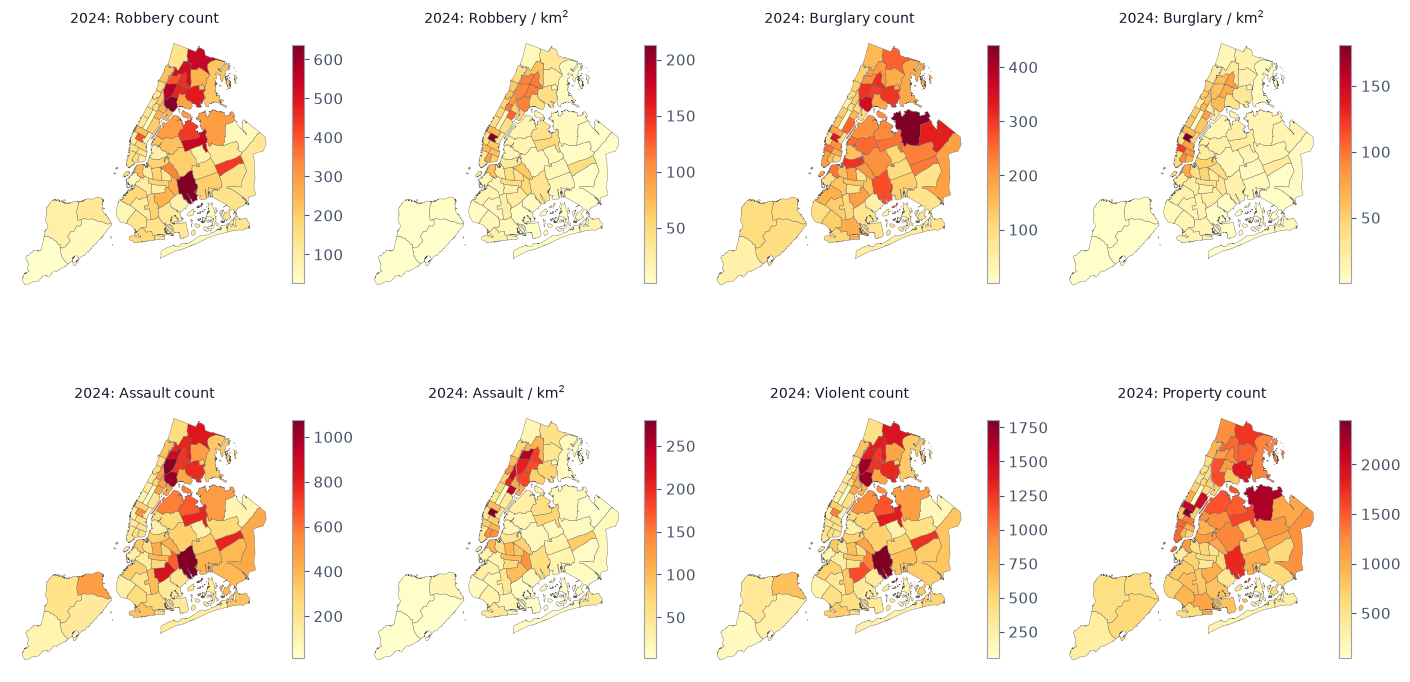

**Top 5 precincts by robbery count (2024)**

,precinct,robbery,robbery_rate
0,75,637,37.988146
1,40,630,112.271759
2,44,560,108.585239
3,47,540,36.210524
4,110,538,51.717807


**Top 5 precincts by robbery rate (2024)**

,precinct,robbery,robbery_rate
0,14,406,213.061423
1,23,250,125.355541
2,28,164,115.422502
3,48,454,115.043747
4,42,471,113.133368


In [4]:
def year_slice(year: int) -> gpd.GeoDataFrame:
    out = panel.loc[panel["year"] == year].copy().reset_index(drop=True)
    if out.empty:
        raise ValueError(f"No rows for year {year}")
    return out


g_cur = year_slice(YEAR_CUR)
g_base = year_slice(YEAR_BASE)

map_cols = [
    ("robbery", "Robbery count"),
    ("robbery_rate", "Robbery / km$^2$"),
    ("burglery", "Burglary count"),
    ("burglery_rate", "Burglary / km$^2$"),
    ("assault", "Assault count"),
    ("assault_rate", "Assault / km$^2$"),
    ("violent", "Violent count"),
    ("property", "Property count"),
]

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5), constrained_layout=True)
for ax, (col, title) in zip(axes.ravel(), map_cols):
    g_cur.plot(
        column=col, cmap="YlOrRd", edgecolor="0.35", linewidth=0.25, ax=ax,
        legend=True, legend_kwds={"shrink": 0.65},
    )
    ax.set_title(f"{YEAR_CUR}: {title}", fontsize=10)
    ax.set_axis_off()
plt.show()

rank = (
    g_cur[["precinct", "robbery", "burglery", "assault", "violent", "property", "area_km2"]]
    .assign(
        robbery_rate=lambda d: d["robbery"] / d["area_km2"],
        burglery_rate=lambda d: d["burglery"] / d["area_km2"],
        assault_rate=lambda d: d["assault"] / d["area_km2"],
    )
)
display(Markdown(f"**Top 5 precincts by robbery count ({YEAR_CUR})**"))
display(rank.nlargest(5, "robbery")[["precinct", "robbery", "robbery_rate"]].reset_index(drop=True))
display(Markdown(f"**Top 5 precincts by robbery rate ({YEAR_CUR})**"))
display(rank.nlargest(5, "robbery_rate")[["precinct", "robbery", "robbery_rate"]].reset_index(drop=True))


### The same color scale across years

The guideline asks for consistent class breaks when comparing maps over time. Each row below uses one color scale for 2000, 2012, and 2024 (harmonized geography, counts per km$^2$), so a lighter map means less crime and not a rescaled legend.

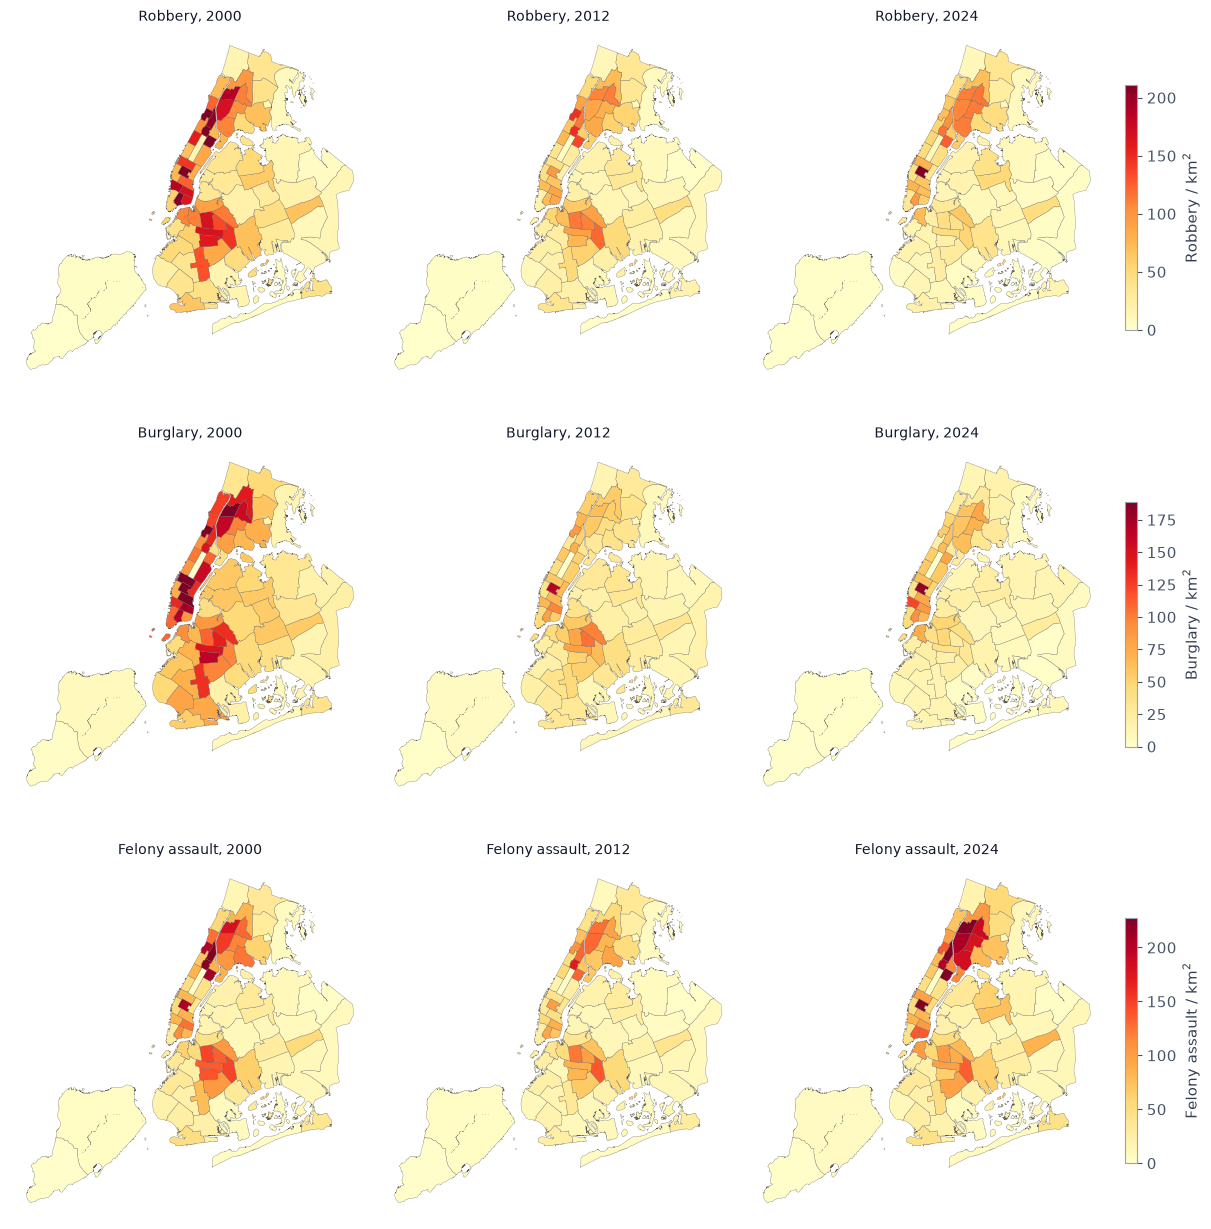

,Robbery / km$^2$,Burglary / km$^2$,Felony assault / km$^2$
year,,,
2000,41.6,49.0,33.1
2012,25.8,24.6,24.9
2024,21.2,16.7,37.4


In [5]:
MAP_YEARS = [2000, 2012, 2024]
fig, axes = plt.subplots(3, 3, figsize=(12, 12.5), constrained_layout=True)
for r, (c, label) in enumerate(FOCUS_COUNTS.items()):
    vmax = float(panel_h.loc[panel_h["year"].isin(MAP_YEARS), f"{c}_rate"].quantile(0.98))
    for k, yr in enumerate(MAP_YEARS):
        ax = axes[r, k]
        panel_h[panel_h["year"] == yr].plot(
            column=f"{c}_rate", cmap="YlOrRd", vmin=0, vmax=vmax, edgecolor="0.35", linewidth=0.2,
            ax=ax, legend=(k == 2), legend_kwds={"shrink": 0.6, "label": f"{label} / km$^2$"},
        )
        ax.set_title(f"{label}, {yr}", fontsize=10)
        ax.set_axis_off()
plt.show()

rate_city = (
    panel_h[panel_h["year"].isin(MAP_YEARS)].groupby("year")[list(FOCUS_COUNTS)].sum()
    / geom_h["area_km2"].sum()
)
rate_city.columns = [f"{FOCUS_COUNTS[c]} / km$^2$" for c in rate_city.columns]
display(rate_city.style.format("{:.1f}"))

## Temporal trends

Annual citywide totals by category, a precinct-year heatmap for robbery, and the 2019-2024 change surface, followed by borough series, indexed trends for each major felony, and Mann-Kendall trend tests. The annual panel supports long-term trend analysis; monthly seasonality would need an incident-level or monthly precinct series.

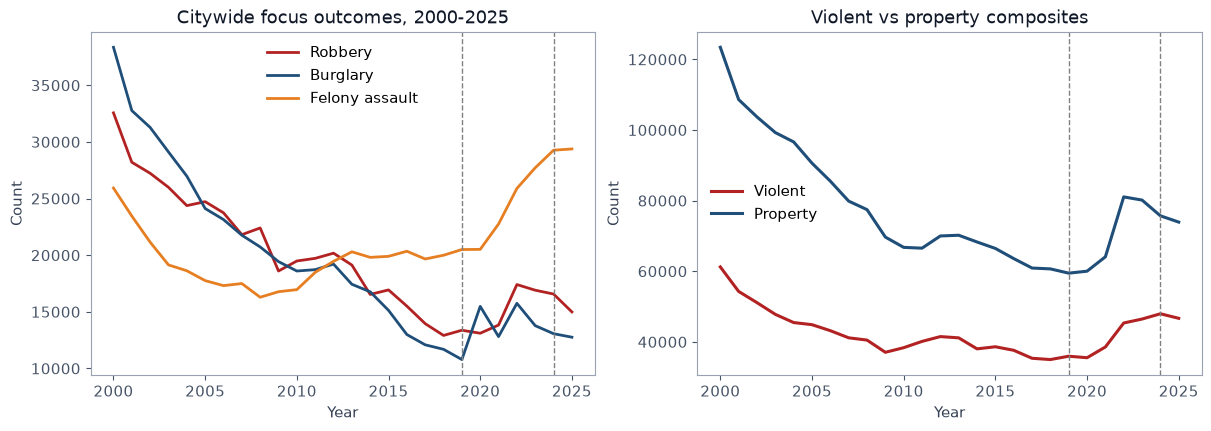

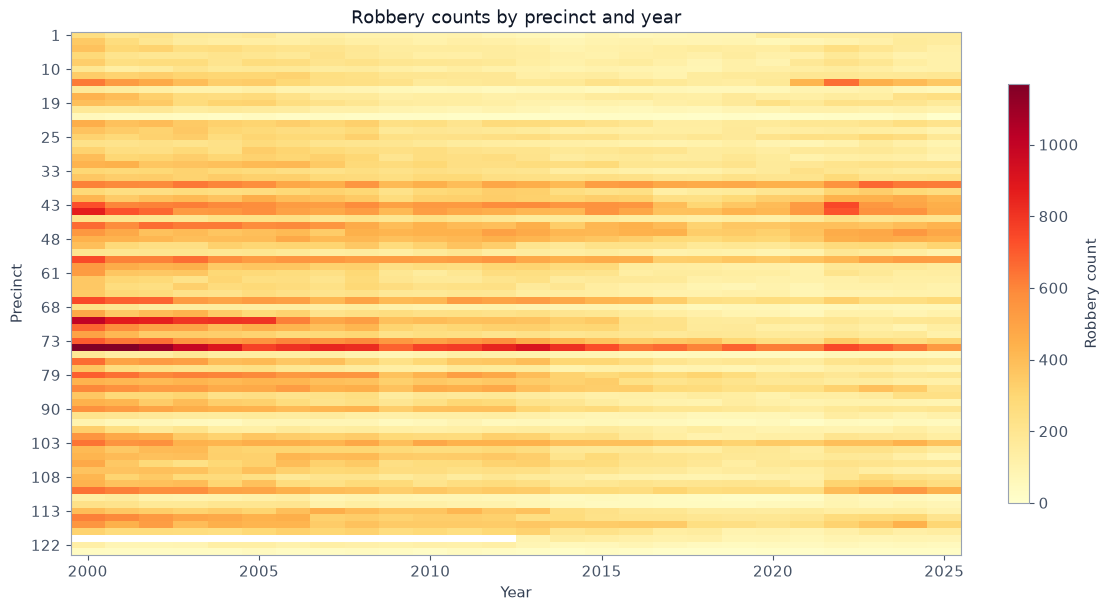

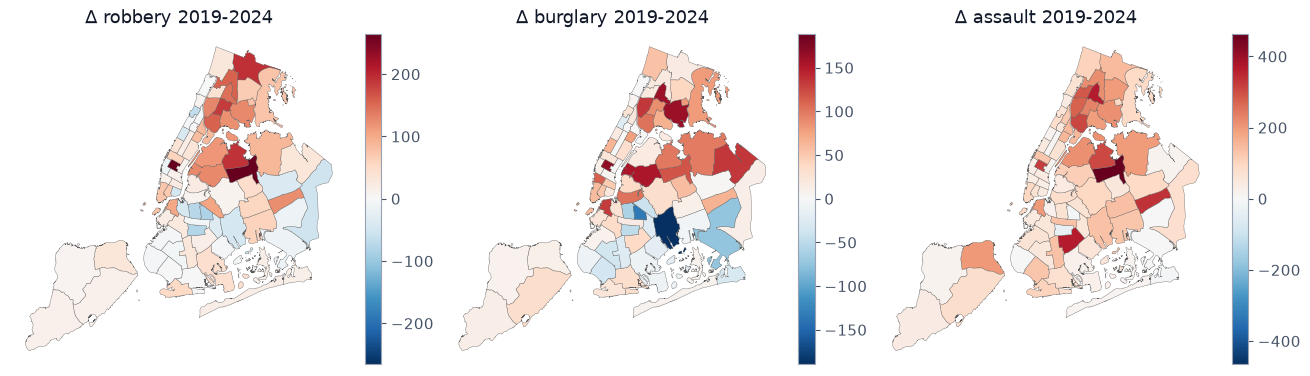

**Robbery:** 13,370 (2019) -> 16,567 (2024) (**+23.9%**)

**Burglary:** 10,783 (2019) -> 13,067 (2024) (**+21.2%**)

**Felony assault:** 20,496 (2019) -> 29,266 (2024) (**+42.8%**)

In [6]:
city = (
    panel.groupby("year", as_index=False)[["robbery", "burglery", "assault", "violent", "property", "tot_7major"]]
    .sum()
    .sort_values("year")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for col, color, label in [
    ("robbery", "#b22222", "Robbery"),
    ("burglery", "#1f4e79", "Burglary"),
    ("assault", "#e67e22", "Felony assault"),
]:
    axes[0].plot(city["year"], city[col], color=color, lw=2, label=label)
axes[0].axvline(YEAR_BASE, color="0.5", ls="--", lw=1)
axes[0].axvline(YEAR_CUR, color="0.5", ls="--", lw=1)
axes[0].set_title("Citywide focus outcomes, 2000-2025")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Count")
axes[0].legend(frameon=False)

axes[1].plot(city["year"], city["violent"], color="#b22222", lw=2.2, label="Violent")
axes[1].plot(city["year"], city["property"], color="#1f4e79", lw=2.2, label="Property")
axes[1].axvline(YEAR_BASE, color="0.5", ls="--", lw=1)
axes[1].axvline(YEAR_CUR, color="0.5", ls="--", lw=1)
axes[1].set_title("Violent vs property composites")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Count")
axes[1].legend(frameon=False)
plt.show()

# Precinct x year heatmap for robbery
heat = (
    panel.pivot_table(index="precinct", columns="year", values="robbery", aggfunc="sum")
    .sort_index()
)
fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
im = ax.imshow(heat.to_numpy(), aspect="auto", cmap="YlOrRd", interpolation="nearest")
ax.set_yticks(range(0, len(heat.index), 5))
ax.set_yticklabels(heat.index[::5])
ax.set_xticks(range(0, len(heat.columns), 5))
ax.set_xticklabels(heat.columns[::5])
ax.set_xlabel("Year")
ax.set_ylabel("Precinct")
ax.set_title("Robbery counts by precinct and year")
fig.colorbar(im, ax=ax, shrink=0.8, label="Robbery count")
plt.show()

# Change 2019-2024
change = g_cur[["precinct", "geometry"]].copy()
for col in ["robbery", "burglery", "assault", "violent", "property"]:
    change[col] = g_cur[col].to_numpy()
    change[f"{col}_base"] = g_base.set_index("precinct").reindex(g_cur["precinct"])[col].to_numpy()
    change[f"delta_{col}"] = change[col] - change[f"{col}_base"]
change = gpd.GeoDataFrame(change, geometry="geometry", crs=g_cur.crs)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), constrained_layout=True)
for ax, col, title in [
    (axes[0], "delta_robbery", f"Δ robbery {YEAR_BASE}-{YEAR_CUR}"),
    (axes[1], "delta_burglery", f"Δ burglary {YEAR_BASE}-{YEAR_CUR}"),
    (axes[2], "delta_assault", f"Δ assault {YEAR_BASE}-{YEAR_CUR}"),
]:
    vmax = np.nanmax(np.abs(change[col]))
    norm = Normalize(vmin=-vmax, vmax=vmax)
    change.plot(
        column=col, cmap="RdBu_r", norm=norm, edgecolor="0.35", linewidth=0.25,
        ax=ax, legend=True, legend_kwds={"shrink": 0.7},
    )
    ax.set_title(title)
    ax.set_axis_off()
plt.show()

for col, label in FOCUS_COUNTS.items():
    b = int(city.loc[city["year"] == YEAR_BASE, col].iloc[0])
    c = int(city.loc[city["year"] == YEAR_CUR, col].iloc[0])
    pct = 100 * (c - b) / b
    display(Markdown(f"**{label}:** {b:,} ({YEAR_BASE}) -> {c:,} ({YEAR_CUR}) (**{pct:+.1f}%**)"))


### Boroughs, offense types, and trend tests

The guideline lists borough differences, violent versus property crime, and small multiples by category. Borough series are area rates on the harmonized panel. Offense series are indexed to 2000 = 100 so that offenses of very different volume can share one axis. Mann-Kendall tests whether each citywide series has a monotonic trend (H4).

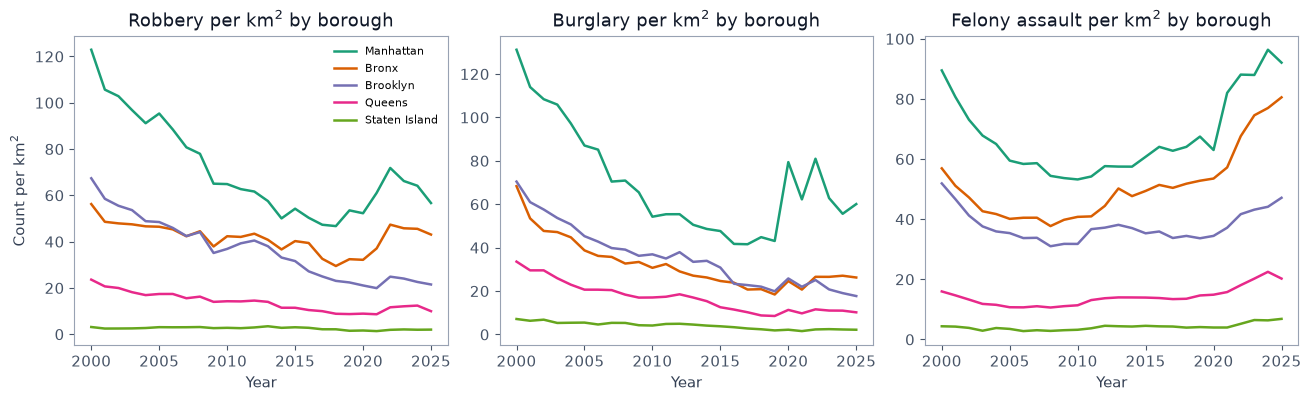

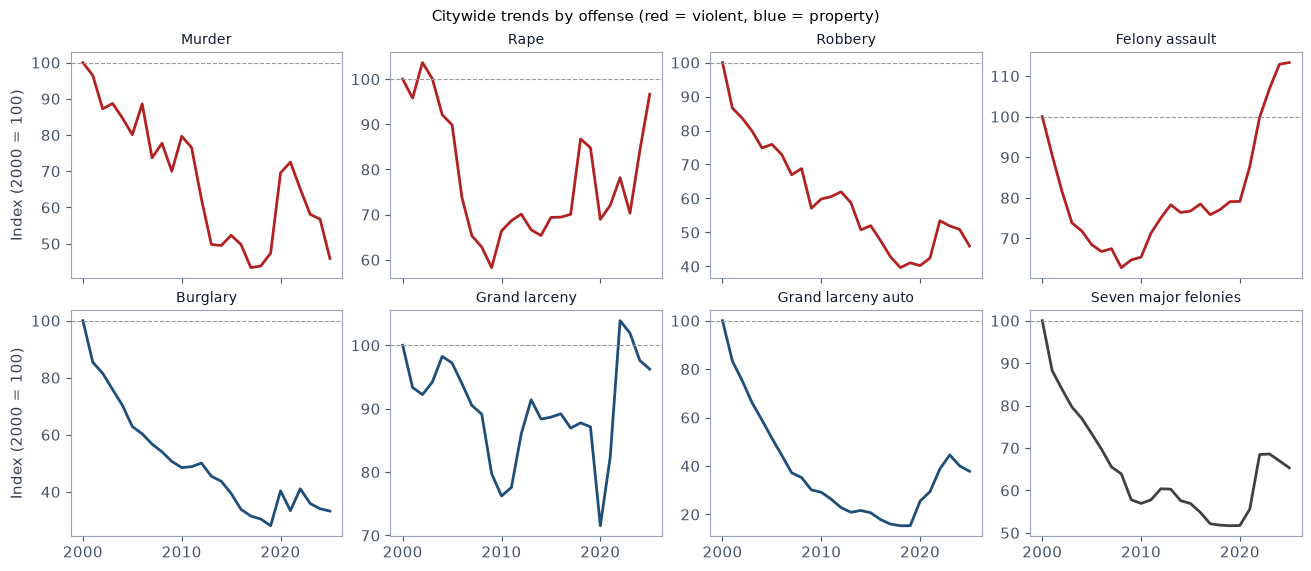

,2000,2025,pct_change,low_year,pct_change_since_low,MK_trend,MK_p,sen_slope_per_year
series,,,,,,,,
Murder,673,309,-54,2017,+6,decreasing,0.0000,-13.7
Rape,"2,068","1,999",-3,2009,+66,no trend,0.7243,-3.5
Robbery,"32,562","14,987",-54,2018,+16,decreasing,0.0000,-703.0
Felony assault,"25,924","29,376",+13,2008,+80,increasing,0.0027,+243.1
Burglary,"38,352","12,756",-67,2019,+18,decreasing,0.0000,-898.8
Grand larceny,"49,631","47,766",-4,2020,+35,no trend,0.2704,-149.7
Grand larceny auto,"35,442","13,396",-62,2018,+147,decreasing,0.0006,-668.5
Seven major felonies,"184,652","120,589",-35,2019,+26,decreasing,0.0001,-2229.3
Violent composite,"61,227","46,671",-24,2018,+33,decreasing,0.0136,-496.8


,Robbery % change 2000-2025,Burglary % change 2000-2025,Felony assault % change 2000-2025
borough,,,
Manhattan,-54,-54,+3
Bronx,-23,-62,+42
Brooklyn,-68,-75,-9
Queens,-58,-70,+27
Staten Island,-36,-69,+56


Between 2000 and 2025 robbery changed by **-54%** and burglary by **-67%**, while felony assault changed by **+13%**. Mann-Kendall labels burglary **decreasing** (p = 0.0000), robbery **decreasing** (p = 0.0000), and felony assault **increasing** (p = 0.0027). Felony assault is **+80%** above its 2008 low, so a monotonic test understates its recent rise. The violent and property composites moved by **-24%** and **-40%**. These differences bear on H3 and H4.

In [7]:
BORO_COLORS = {
    "Manhattan": "#1b9e77", "Bronx": "#d95f02", "Brooklyn": "#7570b3",
    "Queens": "#e7298a", "Staten Island": "#66a61e",
}
boro_area = geom_h.groupby("borough")["area_km2"].sum()
boro = panel_h.groupby(["borough", "year"])[list(FOCUS_COUNTS)].sum()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9), constrained_layout=True)
for ax, (c, label) in zip(axes, FOCUS_COUNTS.items()):
    for b, color in BORO_COLORS.items():
        ax.plot(years, boro.loc[b, c].to_numpy() / boro_area[b], color=color, lw=1.8, label=b)
    ax.set_title(f"{label} per km$^2$ by borough")
    ax.set_xlabel("Year")
axes[0].set_ylabel("Count per km$^2$")
axes[0].legend(frameon=False, fontsize=8)
plt.show()

MAJOR = {
    "murder": "Murder", "rape": "Rape", "robbery": "Robbery", "assault": "Felony assault",
    "burglery": "Burglary", "gdlarceny": "Grand larceny", "gdlarcauto": "Grand larceny auto",
    "tot_7major": "Seven major felonies",
}
city_all = panel_h.groupby("year")[[*MAJOR, "violent", "property"]].sum()
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6), constrained_layout=True, sharex=True)
for ax, (c, label) in zip(axes.ravel(), MAJOR.items()):
    is_violent = c in COMPOSITES["violent"]
    color = "#b22222" if is_violent else ("0.25" if c == "tot_7major" else "#1f4e79")
    ax.plot(years, 100 * city_all[c] / city_all[c].iloc[0], color=color, lw=2)
    ax.axhline(100, color="0.6", lw=0.8, ls="--")
    ax.set_title(label, fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel(f"Index ({years[0]} = 100)")
fig.suptitle("Citywide trends by offense (red = violent, blue = property)", fontsize=11)
plt.show()

trend_rows = []
for c in [*MAJOR, "violent", "property"]:
    s = city_all[c].to_numpy(float)
    res = mk.original_test(s)
    trend_rows.append({
        "series": MAJOR.get(c, c.capitalize() + " composite"),
        f"{years[0]}": s[0], f"{years[-1]}": s[-1],
        "pct_change": 100 * (s[-1] / s[0] - 1),
        "low_year": years[int(np.argmin(s))],
        "pct_change_since_low": 100 * (s[-1] / s.min() - 1),
        "MK_trend": res.trend, "MK_p": res.p, "sen_slope_per_year": res.slope,
    })
trend_tbl = pd.DataFrame(trend_rows).set_index("series")
display(trend_tbl.style.format({
    f"{years[0]}": "{:,.0f}", f"{years[-1]}": "{:,.0f}", "pct_change": "{:+.0f}",
    "pct_change_since_low": "{:+.0f}", "MK_p": "{:.4f}", "sen_slope_per_year": "{:+.1f}",
}))

boro_chg = 100 * (boro.xs(years[-1], level="year") / boro.xs(years[0], level="year") - 1)
boro_chg.columns = [f"{FOCUS_COUNTS[c]} % change {years[0]}-{years[-1]}" for c in boro_chg.columns]
display(boro_chg.reindex(list(BORO_COLORS)).style.format("{:+.0f}"))

t = trend_tbl
display(Markdown(
    f"Between {years[0]} and {years[-1]} robbery changed by **{t.loc['Robbery', 'pct_change']:+.0f}%** and burglary by "
    f"**{t.loc['Burglary', 'pct_change']:+.0f}%**, while felony assault changed by **{t.loc['Felony assault', 'pct_change']:+.0f}%**. "
    f"Mann-Kendall labels burglary **{t.loc['Burglary', 'MK_trend']}** (p = {t.loc['Burglary', 'MK_p']:.4f}), robbery "
    f"**{t.loc['Robbery', 'MK_trend']}** (p = {t.loc['Robbery', 'MK_p']:.4f}), and felony assault "
    f"**{t.loc['Felony assault', 'MK_trend']}** (p = {t.loc['Felony assault', 'MK_p']:.4f}). "
    f"Felony assault is **{t.loc['Felony assault', 'pct_change_since_low']:+.0f}%** above its "
    f"{int(t.loc['Felony assault', 'low_year'])} low, so a monotonic test understates its recent rise. "
    f"The violent and property composites moved by **{t.loc['Violent composite', 'pct_change']:+.0f}%** and "
    f"**{t.loc['Property composite', 'pct_change']:+.0f}%**. These differences bear on H3 and H4."
))

## Interactive Leaflet maps (OpenStreetMap)

Folium builds Leaflet.js maps. Choropleths for 2024 robbery rates and the 2019-2024 robbery change sit on an OpenStreetMap basemap.


In [8]:
def leaflet_choropleth(
    gdf: gpd.GeoDataFrame,
    column: str,
    title: str,
    cmap_name: str = "YlOrRd",
    diverging: bool = False,
    zoom_start: int = 10,
) -> folium.Map:
    """Choropleth on an OpenStreetMap basemap (WGS84)."""
    g = gdf[["precinct", column, "geometry"]].copy()
    g["geometry"] = g.geometry.simplify(30, preserve_topology=True)  # about 9 m; keeps the notebook small
    g = g.to_crs(4326)
    g = g[g.geometry.notna() & ~g.geometry.is_empty].copy()
    g[column] = pd.to_numeric(g[column], errors="coerce")
    g = g.dropna(subset=[column])
    g["precinct"] = g["precinct"].astype(int)
    g["value_label"] = g[column].map(lambda v: f"{v:,.1f}" if abs(v) < 100 else f"{v:,.0f}")

    bounds = g.total_bounds
    center = [float((bounds[1] + bounds[3]) / 2), float((bounds[0] + bounds[2]) / 2)]

    if diverging:
        vmax = float(np.nanmax(np.abs(g[column])))
        vmin, vmax = -vmax, vmax
        colors = ["#2166ac", "#f7f7f7", "#b2182b"]
    else:
        vmin, vmax = float(g[column].min()), float(g[column].max())
        mpl_cmap = plt.get_cmap(cmap_name)
        colors = [
            f"#{int(r * 255):02x}{int(gg * 255):02x}{int(b * 255):02x}"
            for r, gg, b, _a in (mpl_cmap(x) for x in np.linspace(0.15, 0.95, 8))
        ]

    colormap = LinearColormap(colors=colors, vmin=vmin, vmax=vmax, caption=title)
    m = folium.Map(
        location=center, zoom_start=zoom_start, tiles="OpenStreetMap", control_scale=True
    )

    def style_function(feature):
        val = feature["properties"].get(column)
        return {
            "fillColor": colormap(val) if val is not None else "#cccccc",
            "color": "#333333",
            "weight": 0.6,
            "fillOpacity": 0.72,
        }

    folium.GeoJson(
        data=json.loads(g.to_json()),
        name=title,
        style_function=style_function,
        tooltip=folium.GeoJsonTooltip(
            fields=["precinct", "value_label"],
            aliases=["Precinct", title],
            sticky=True,
        ),
        highlight_function=lambda _f: {"weight": 2, "color": "#000000", "fillOpacity": 0.9},
    ).add_to(m)
    colormap.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    return m


m_rate = leaflet_choropleth(
    g_cur, "robbery_rate", f"Robbery rate / km2 ({YEAR_CUR})"
)
m_delta = leaflet_choropleth(
    change, "delta_robbery", f"Change in robbery ({YEAR_BASE}-{YEAR_CUR})", diverging=True
)
display(Markdown(f"### Robbery rate, {YEAR_CUR} (Leaflet + OSM)"))
display(m_rate)
display(Markdown(f"### Robbery change, {YEAR_BASE}-{YEAR_CUR} (Leaflet + OSM)"))
display(m_delta)


### Robbery rate, 2024 (Leaflet + OSM)

### Robbery change, 2019-2024 (Leaflet + OSM)

## Global spatial autocorrelation

Queen contiguity on precinct polygons. Moran's I is computed each year for robbery, burglary, assault, violent, and property to test H1 and H3. The yearly path uses the harmonized 75-unit panel so that all 26 years are covered; the 2024 scatter and the local statistics use the 77 precincts.

Spatial Weights (W)
  Observations        77
  Transform           row
  Min neighbors       1
  Mean neighbors      4.260
  Max neighbors       7
  Islands             0
  Components          3
  Nonzero weights     328


Queen weights on **77** precincts: **0** island(s), **3** component(s).

harmonized weights: 75 units, 3 component(s)


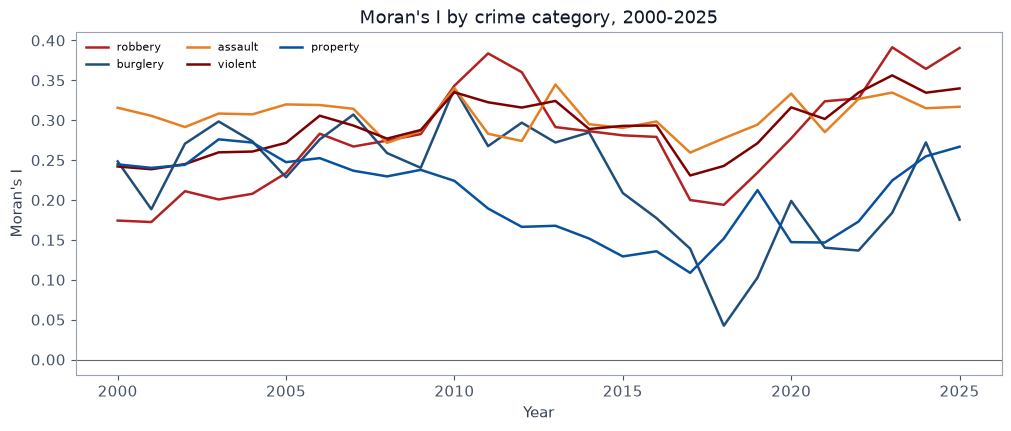

,I,p_value,z_score
outcome,,,
robbery,0.364,0.001,4.58
burglery,0.272,0.001,3.45
assault,0.315,0.003,3.97
violent,0.335,0.002,4.21
property,0.255,0.002,3.24


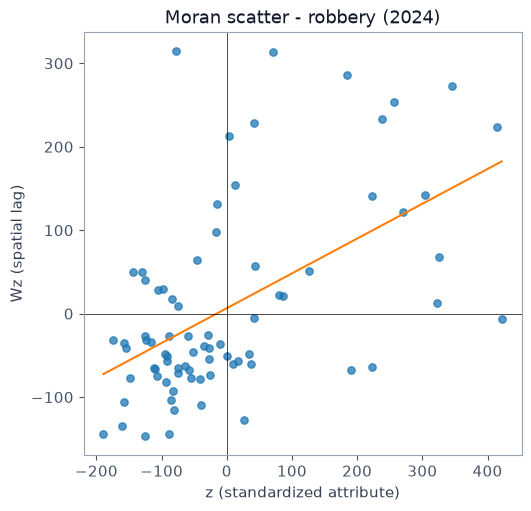

In 2024, Moran's I for robbery is **0.417** (p = **0.001**). Across 26 years and five outcomes, Moran's I ranges from **0.04** to **0.39** and is significant at 0.05 in **89%** of the outcome-years, supporting H1. Mean I over the period is **0.29** for the violent composite and **0.21** for the property composite (H3).

In [9]:
geom = g_cur[["precinct", "geometry"]].copy().reset_index(drop=True)
w = Queen(geom.set_index("precinct"), transform="row")
print(w.summary())
display(Markdown(
    f"Queen weights on **{w.n}** precincts: "
    f"**{len(w.islands())}** island(s), **{w.n_components()}** component(s)."
))

w_h = Queen(geom_h, transform="row")
assert list(w_h.id_order) == units
print(f"harmonized weights: {w_h.n} units, {w_h.n_components()} component(s)")

outcomes = ["robbery", "burglery", "assault", "violent", "property"]
moran_rows = []
for year, sub in panel_h.groupby("year"):
    for col in outcomes:
        s = sub.set_index("precinct")[col].reindex(w_h.id_order)
        if s.isna().any():
            continue
        mi = Moran(s.to_numpy(float), w_h, permutations=PERM, seed=SEED)
        moran_rows.append(
            {"year": int(year), "outcome": col, "I": mi.I, "p_value": mi.p_value, "z_score": mi.z_score}
        )
moran_ts = pd.DataFrame(moran_rows)

fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
colors = {
    "robbery": "#b22222", "burglery": "#1f4e79", "assault": "#e67e22",
    "violent": "#7f0000", "property": "#08519c",
}
for col, color in colors.items():
    d = moran_ts[moran_ts["outcome"] == col]
    ax.plot(d["year"], d["I"], color=color, lw=1.8, label=col)
ax.axhline(0, color="0.4", lw=0.8)
ax.set_title("Moran's I by crime category, 2000-2025")
ax.set_xlabel("Year")
ax.set_ylabel("Moran's I")
ax.legend(frameon=False, ncol=3, fontsize=8)
plt.show()

cur_I = (
    moran_ts[moran_ts["year"] == YEAR_CUR]
    .set_index("outcome")[["I", "p_value", "z_score"]]
    .reindex(outcomes)
)
display(cur_I.style.format({"I": "{:.3f}", "p_value": "{:.3f}", "z_score": "{:.2f}"}))

y_rob = g_cur.set_index("precinct")["robbery"].reindex(w.id_order).to_numpy(float)
mi_rob = Moran(y_rob, w, permutations=PERM, seed=SEED)
fig, ax = plt.subplots(figsize=(5.2, 5), constrained_layout=True)
_ = moran_scatter(mi_rob, ax=ax, s=28, alpha=0.75)
ax.set_title(f"Moran scatter - robbery ({YEAR_CUR})")
plt.show()
display(Markdown(
    f"In {YEAR_CUR}, Moran's I for robbery is **{mi_rob.I:.3f}** "
    f"(p = **{mi_rob.p_value:.3f}**). Across {moran_ts['year'].nunique()} years and five outcomes, Moran's I ranges from "
    f"**{moran_ts['I'].min():.2f}** to **{moran_ts['I'].max():.2f}** and is significant at {ALPHA} in **{(moran_ts['p_value'] < ALPHA).mean() * 100:.0f}%** of the outcome-years, supporting H1. "
    f"Mean I over the period is **{moran_ts[moran_ts['outcome'] == 'violent']['I'].mean():.2f}** for the violent composite and "
    f"**{moran_ts[moran_ts['outcome'] == 'property']['I'].mean():.2f}** for the property composite (H3)."
))


### Sensitivity to the weights and to the exposure

The guideline names Queen contiguity, Rook contiguity, and distance-based weights. Contiguity leaves the precinct graph in several components because boroughs are separated by water, so a k-nearest-neighbor graph on centroids (k = 4) is a useful check: it links precincts across the rivers. Counts and area rates are both tested, since a count partly reflects how large a precinct is.

In [10]:
geom_idx = geom.set_index("precinct")
weight_sets = {
    "Queen": w,
    "Rook": Rook(geom_idx, transform="row"),
    "KNN-4": KNN(geom_idx, k=4, transform="row"),
}
graph_tbl = pd.DataFrame(
    {
        "components": {k: v.n_components() for k, v in weight_sets.items()},
        "mean neighbors": {k: float(np.mean(v.cardinalities())) for k, v in weight_sets.items()},
    }
)
display(graph_tbl.style.format({"mean neighbors": "{:.2f}"}))

cur_idx = g_cur.set_index("precinct").reindex(w.id_order)
sens_rows = []
for c, label in FOCUS_COUNTS.items():
    for measure, colname in [("count", c), ("rate per km2", f"{c}_rate")]:
        row = {"outcome": label, "measure": measure}
        for wname, ww in weight_sets.items():
            mi = Moran(cur_idx[colname].to_numpy(float), ww, permutations=PERM, seed=SEED)
            row[f"I {wname}"] = mi.I
            row[f"p {wname}"] = mi.p_value
        sens_rows.append(row)
sens_tbl = pd.DataFrame(sens_rows).set_index(["outcome", "measure"])
display(sens_tbl.style.format("{:.3f}"))

p_cols = [c for c in sens_tbl.columns if c.startswith("p ")]
n_sig = int((sens_tbl[p_cols] < ALPHA).to_numpy().sum())
not_sig = [f"{o} ({m})" for (o, m), r in sens_tbl[p_cols].iterrows() if (r >= ALPHA).any()]
display(Markdown(
    f"In {YEAR_CUR}, **{n_sig}** of the **{sens_tbl[p_cols].size}** outcome-measure-weights combinations are significant at {ALPHA}. "
    + (f"Not significant under at least one definition: **{'; '.join(not_sig)}**. " if not_sig else "Every combination is significant. ")
    + f"Queen contiguity is kept for the rest of the notebook."
))

,components,mean neighbors
Queen,3,4.26
Rook,3,4.13
KNN-4,1,4.00


In 2024, **18** of the **18** outcome-measure-weights combinations are significant at 0.05. Every combination is significant. Queen contiguity is kept for the rest of the notebook.

## Local hotspots: LISA and Gi*

Classify precincts into HH / LL / HL / LH (LISA) and hot/cold spots (Gi*) for 2024 robbery and for the 2019-2024 robbery change. The first maps use uncorrected LISA p-values; the next cell applies the multiple-testing adjustment the guideline asks for and compares the three focus outcomes.

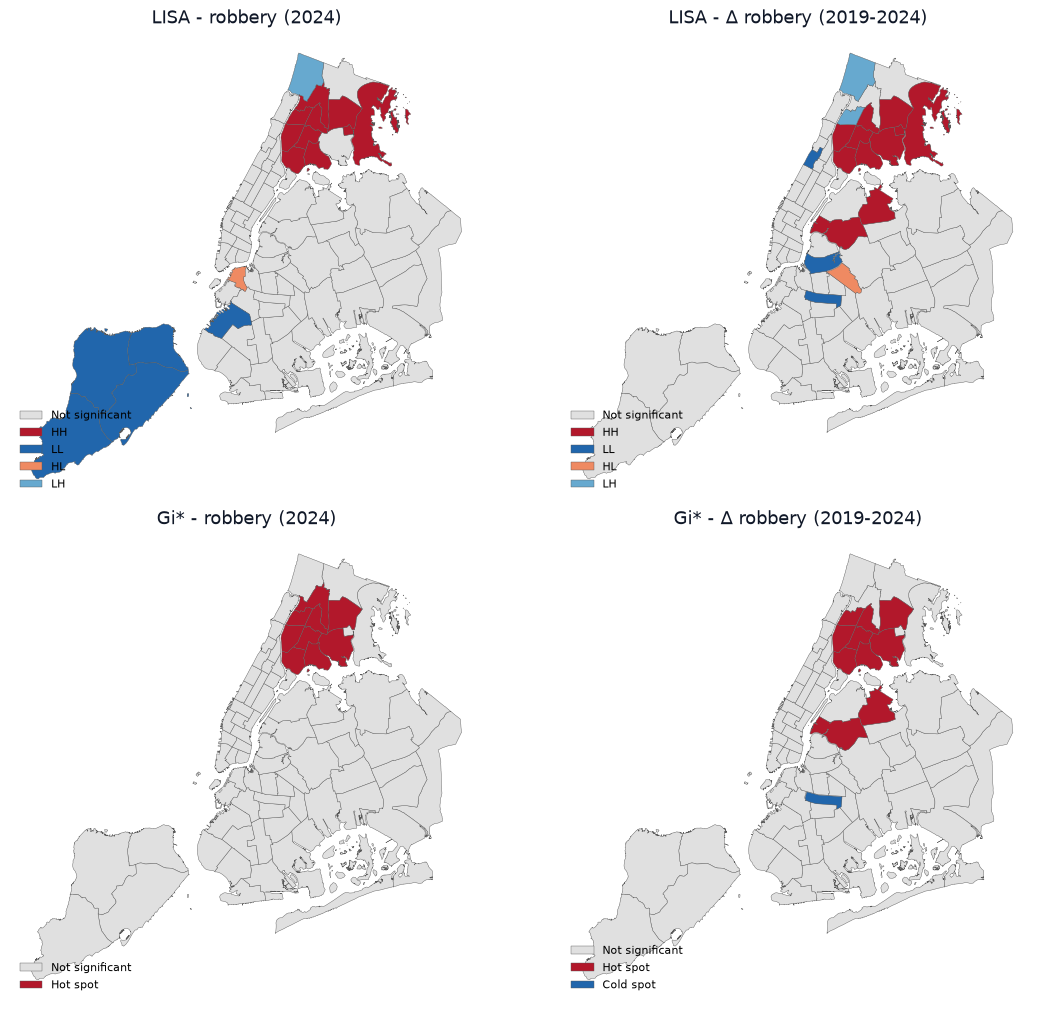

**LISA robbery 2024**

,label,n
0,Not significant,61
1,HH,9
2,LL,5
3,LH,1
4,HL,1


**Gi* robbery 2024**

,label,n
0,Not significant,68
1,Hot spot,9


LISA here uses uncorrected permutation p-values; the FDR-adjusted version follows. Gi* uses analytic inference with 90/95/99% bands collapsed for mapping.

In [11]:
def gi_group(label: str) -> str:
    lab = str(label)
    if lab.startswith("Hot"):
        return "Hot spot"
    if lab.startswith("Cold"):
        return "Cold spot"
    return "Not significant"


y_rob = g_cur.set_index("precinct")["robbery"].reindex(w.id_order).to_numpy(float)
y_drob = change.set_index("precinct")["delta_robbery"].reindex(w.id_order).to_numpy(float)

lisa_cur = local_moran_clusters(
    y_rob, w, permutations=PERM, correction="none", alpha=ALPHA, seed=SEED
)
lisa_delta = local_moran_clusters(
    y_drob, w, permutations=PERM, correction="none", alpha=ALPHA, seed=SEED
)
gi_cur = getis_ord_gi(y_rob, w, star=True, inference="analytic", alpha=ALPHA, seed=SEED)
gi_delta = getis_ord_gi(y_drob, w, star=True, inference="analytic", alpha=ALPHA, seed=SEED)

cluster = geom.set_index("precinct").reindex(w.id_order).copy()
cluster["precinct"] = cluster.index.astype(int)
cluster["robbery"] = y_rob
cluster["delta_robbery"] = y_drob
cluster["lisa_2024"] = list(lisa_cur.labels)
cluster["lisa_delta"] = list(lisa_delta.labels)
cluster["gi_2024"] = [gi_group(x) for x in gi_cur.labels]
cluster["gi_delta"] = [gi_group(x) for x in gi_delta.labels]
cluster = gpd.GeoDataFrame(cluster, geometry="geometry", crs=geom.crs)

LISA_COLORS = {
    "Not significant": "#e0e0e0",
    "HH": "#b2182b",
    "LL": "#2166ac",
    "HL": "#ef8a62",
    "LH": "#67a9cf",
}
GI_COLORS = {
    "Not significant": "#e0e0e0",
    "Hot spot": "#b2182b",
    "Cold spot": "#2166ac",
}

fig, axes = plt.subplots(2, 2, figsize=(11, 10), constrained_layout=True)
specs = [
    (axes[0, 0], "lisa_2024", LISA_COLORS, f"LISA - robbery ({YEAR_CUR})"),
    (axes[0, 1], "lisa_delta", LISA_COLORS, f"LISA - Δ robbery ({YEAR_BASE}-{YEAR_CUR})"),
    (axes[1, 0], "gi_2024", GI_COLORS, f"Gi* - robbery ({YEAR_CUR})"),
    (axes[1, 1], "gi_delta", GI_COLORS, f"Gi* - Δ robbery ({YEAR_BASE}-{YEAR_CUR})"),
]
for ax, col, palette, title in specs:
    for label, color in palette.items():
        part = cluster[cluster[col] == label]
        if len(part):
            part.plot(ax=ax, color=color, edgecolor="0.35", linewidth=0.3, label=label)
    ax.set_title(title)
    ax.set_axis_off()
    ax.legend(loc="lower left", fontsize=8, frameon=False)
plt.show()

display(Markdown("**LISA robbery 2024**"))
display(cluster["lisa_2024"].value_counts().rename_axis("label").reset_index(name="n"))
display(Markdown("**Gi* robbery 2024**"))
display(cluster["gi_2024"].value_counts().rename_axis("label").reset_index(name="n"))
display(Markdown(
    "LISA here uses uncorrected permutation p-values; the FDR-adjusted version follows. "
    "Gi* uses analytic inference with 90/95/99% bands collapsed for mapping."
))


### FDR-adjusted LISA for robbery, burglary, and felony assault

With 77 simultaneous local tests, some uncorrected clusters are expected by chance. The Benjamini-Hochberg adjustment is applied with more permutations (`PERM_LOCAL`). Comparing the three outcomes shows whether violent and property crime concentrate in the same precincts (H3).

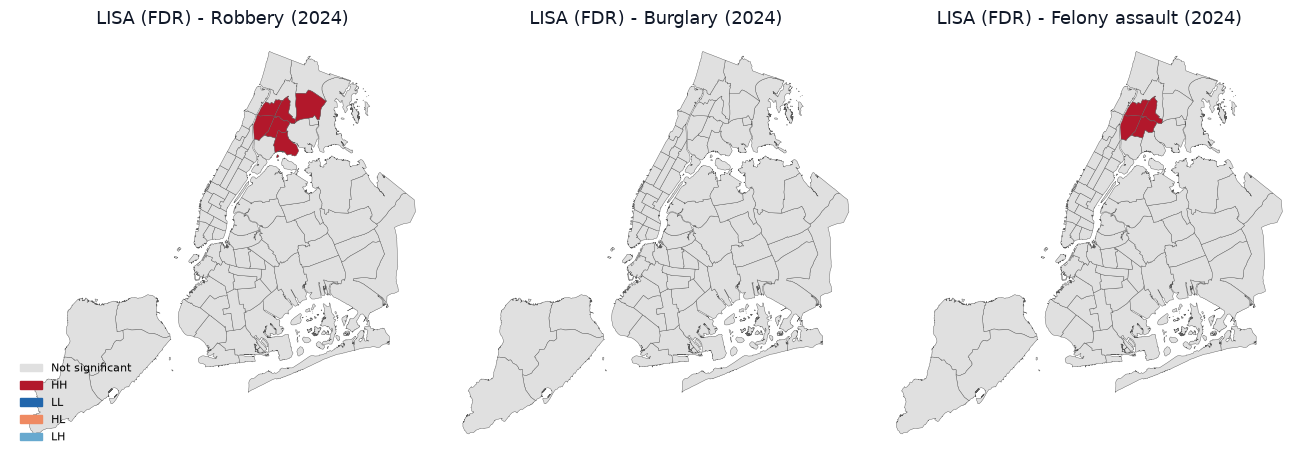

,HH uncorrected,HH FDR,LL uncorrected,LL FDR,outliers uncorrected,outliers FDR
outcome,,,,,,
Robbery,9,6,5,0,2,0
Burglary,10,0,7,0,1,0
Felony assault,8,4,5,0,1,0


**Overlap of FDR High-High precincts (Jaccard index)**

,Robbery,Burglary,Felony assault
Robbery,1.00,0.00,0.67
Burglary,0.00,no HH,0.00
Felony assault,0.67,0.00,1.00


Robbery High-High precincts (FDR): [41, 42, 44, 46, 48, 49]
Burglary High-High precincts (FDR): none
Felony assault High-High precincts (FDR): [42, 44, 46, 48]


After FDR adjustment the High-High counts are **6** (robbery), **0** (burglary), and **4** (felony assault), against **9**, **10**, and **8** uncorrected. The robbery and assault High-High sets overlap with a Jaccard index of **0.67**. Burglary has no High-High precinct that survives the adjustment.

In [12]:
def lisa_pair(values):
    # Uncorrected and FDR-adjusted LISA labels. The resolution warning for FDR is silenced;
    # the table below reports how many precincts survive.
    unc = local_moran_clusters(values, w, permutations=PERM_LOCAL, correction="none", alpha=ALPHA, seed=SEED)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        fdr = local_moran_clusters(values, w, permutations=PERM_LOCAL, correction="fdr", alpha=ALPHA, seed=SEED)
    return np.asarray(unc.labels), np.asarray(fdr.labels)


lisa_rows, hh_sets = [], {}
fig, axes = plt.subplots(1, 3, figsize=(13, 5), constrained_layout=True)
for ax, (c, label) in zip(axes, FOCUS_COUNTS.items()):
    unc, fdr = lisa_pair(cur_idx[c].to_numpy(float))
    cluster[f"lisa_fdr_{c}"] = fdr
    hh_sets[label] = set(np.asarray(w.id_order)[fdr == "HH"].tolist())
    lisa_rows.append({
        "outcome": label,
        "HH uncorrected": int((unc == "HH").sum()), "HH FDR": int((fdr == "HH").sum()),
        "LL uncorrected": int((unc == "LL").sum()), "LL FDR": int((fdr == "LL").sum()),
        "outliers uncorrected": int(np.isin(unc, ["HL", "LH"]).sum()),
        "outliers FDR": int(np.isin(fdr, ["HL", "LH"]).sum()),
    })
    for lab, color in LISA_COLORS.items():
        part = cluster[cluster[f"lisa_fdr_{c}"] == lab]
        if len(part):
            part.plot(ax=ax, color=color, edgecolor="0.35", linewidth=0.3)
    ax.set_title(f"LISA (FDR) - {label} ({YEAR_CUR})")
    ax.set_axis_off()
axes[0].legend(
    handles=[Patch(color=col_, label=lab) for lab, col_ in LISA_COLORS.items()],
    loc="lower left", fontsize=8, frameon=False,
)
plt.show()

lisa_tbl = pd.DataFrame(lisa_rows).set_index("outcome")
display(lisa_tbl)

labels_ = list(hh_sets)
jac = pd.DataFrame(index=labels_, columns=labels_, dtype=float)
for a in labels_:
    for b in labels_:
        union = hh_sets[a] | hh_sets[b]
        jac.loc[a, b] = len(hh_sets[a] & hh_sets[b]) / len(union) if union else np.nan
display(Markdown("**Overlap of FDR High-High precincts (Jaccard index)**"))
display(jac.style.format("{:.2f}", na_rep="no HH"))
for label, s in hh_sets.items():
    print(f"{label} High-High precincts (FDR): {sorted(s) if s else 'none'}")

display(Markdown(
    f"After FDR adjustment the High-High counts are **{lisa_tbl.loc['Robbery', 'HH FDR']}** (robbery), "
    f"**{lisa_tbl.loc['Burglary', 'HH FDR']}** (burglary), and **{lisa_tbl.loc['Felony assault', 'HH FDR']}** (felony assault), "
    f"against **{lisa_tbl.loc['Robbery', 'HH uncorrected']}**, **{lisa_tbl.loc['Burglary', 'HH uncorrected']}**, and "
    f"**{lisa_tbl.loc['Felony assault', 'HH uncorrected']}** uncorrected. "
    f"The robbery and assault High-High sets overlap with a Jaccard index of "
    f"**{jac.loc['Robbery', 'Felony assault']:.2f}**. "
    + (f"Burglary overlaps with robbery at **{jac.loc['Robbery', 'Burglary']:.2f}**."
       if hh_sets["Burglary"] else "Burglary has no High-High precinct that survives the adjustment.")
))

## Space-time emerging hotspots

Track Gi* hot/cold membership in every year, then classify each unit's trajectory (new, persistent, intensifying, diminishing, sporadic), following the Part 9.3 emerging-hotspot logic and *crime analysis.qmd* Section 5 / Model 6. The classification runs on the harmonized panel, so every unit has all 26 years, and is repeated for robbery, burglary, and felony assault. Gi* uses analytic p-values with the FDR adjustment across units.

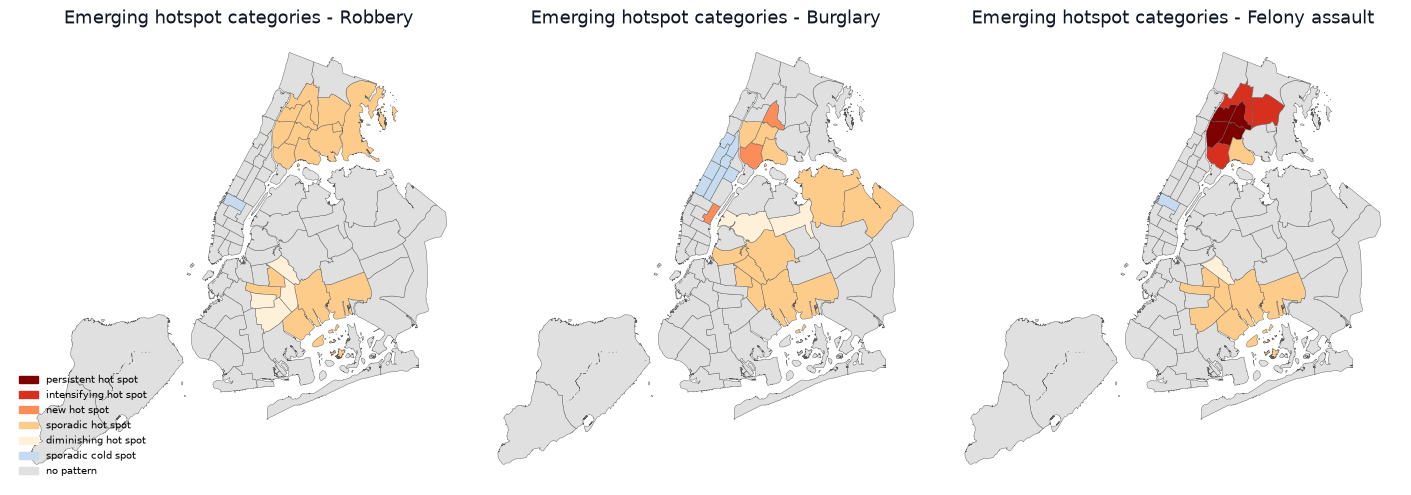

,Robbery,Burglary,Felony assault
persistent hot spot,0,0,4
intensifying hot spot,0,0,3
new hot spot,0,3,0
sporadic hot spot,15,12,8
diminishing hot spot,4,2,1
sporadic cold spot,1,8,1
no pattern,55,50,58


,units ever hot,units hot in >= half of years,max hot years,hot units per year (mean),units with significant MK trend,of which decreasing
Robbery,19,6,21,7.0,68,68
Burglary,17,0,12,2.1,67,67
Felony assault,16,8,26,8.0,39,6


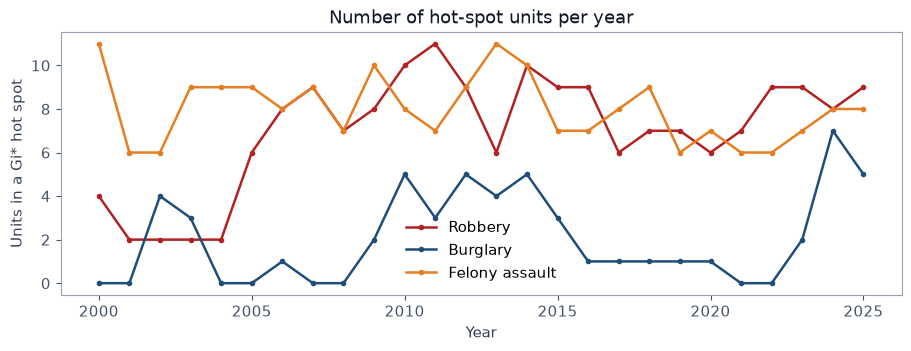

Robbery: **19** of 75 units are in a hot spot at least once, **6** in at least half of the years, and the longest run is **21** of 26 years. Felony assault: **16** ever hot, **8** in at least half of the years. Burglary: **17** ever hot. Robbery and assault receive the same category in **84%** of units; robbery and burglary in **61%**. Mann-Kendall finds a significant count trend (raw alpha = 0.05) in **68** units for robbery, **67** for burglary, and **39** for felony assault.

In [13]:
precincts = units
n_t, n_i = N_T, N_U


def emerging_hotspots(column: str):
    # Gi* membership by year plus a Mann-Kendall trend, classified per unit.
    series = mat(column).T  # (years, units)
    hot_matrix = np.zeros((n_t, n_i), dtype=int)
    cold_matrix = np.zeros((n_t, n_i), dtype=int)
    for t in range(n_t):
        gi = getis_ord_gi(series[t], w_h, star=True, inference="analytic", alpha=ALPHA, seed=SEED)
        labs = np.array([gi_group(x) for x in gi.labels])
        hot_matrix[t] = labs == "Hot spot"
        cold_matrix[t] = labs == "Cold spot"

    mk_rows = []
    for j, pct in enumerate(precincts):
        res = mk.original_test(series[:, j])
        mk_rows.append({
            "precinct": pct, "trend": res.trend, "p": res.p,
            "significant": res.p < ALPHA, "slope": res.slope,
        })
    mk_df = pd.DataFrame(mk_rows).set_index("precinct")

    def categorize(j: int) -> str:
        n_hot, n_cold = hot_matrix[:, j].sum(), cold_matrix[:, j].sum()
        if n_hot > 0 and n_cold > 0:
            return "oscillating"
        if n_hot == 0 and n_cold == 0:
            return "no pattern"
        is_hot = n_hot > 0
        n_x = n_hot if is_hot else n_cold
        m = hot_matrix if is_hot else cold_matrix
        last3, first3 = m[-3:, j].sum(), m[:3, j].sum()
        pct = precincts[j]
        trend_sig = bool(mk_df.loc[pct, "significant"])
        increasing = mk_df.loc[pct, "trend"] == "increasing"
        strengthening = increasing if is_hot else (not increasing)

        if n_x == 1 and last3 >= 1 and first3 == 0:
            label = "new"
        elif n_x >= 0.9 * n_t:
            label = "persistent"
        elif trend_sig and strengthening and last3 >= 2:
            label = "intensifying"
        elif trend_sig and (not strengthening) and first3 >= 1 and last3 == 0:
            label = "diminishing"
        else:
            label = "sporadic"
        return f"{label} {'hot' if is_hot else 'cold'} spot"

    cats = pd.Series([categorize(j) for j in range(n_i)], index=precincts, name="category")
    return cats, hot_matrix, cold_matrix, mk_df


palette = {
    "persistent hot spot": "#7f0000",
    "intensifying hot spot": "#d7301f",
    "new hot spot": "#fc8d59",
    "sporadic hot spot": "#fdcc8a",
    "diminishing hot spot": "#fef0d9",
    "persistent cold spot": "#08306b",
    "intensifying cold spot": "#2171b5",
    "new cold spot": "#6baed6",
    "sporadic cold spot": "#c6dbef",
    "diminishing cold spot": "#deebf7",
    "oscillating": "#8c510a",
    "no pattern": "#e0e0e0",
}

eh = {c: emerging_hotspots(c) for c in FOCUS_COUNTS}
categories, hot_matrix, cold_matrix, mk_df = eh["robbery"]

emerge = geom_h[["geometry"]].copy()
emerge.index.name = "precinct"
for c in FOCUS_COUNTS:
    emerge[f"category_{c}"] = eh[c][0].reindex(emerge.index).to_numpy()
    emerge[f"hot_years_{c}"] = eh[c][1].sum(axis=0)
emerge["category"] = emerge["category_robbery"]

fig, axes = plt.subplots(1, 3, figsize=(14, 5.4), constrained_layout=True)
for ax, (c, label) in zip(axes, FOCUS_COUNTS.items()):
    for lab, color in palette.items():
        part = emerge[emerge[f"category_{c}"] == lab]
        if len(part):
            part.plot(ax=ax, color=color, edgecolor="0.35", linewidth=0.3)
    ax.set_title(f"Emerging hotspot categories - {label}")
    ax.set_axis_off()
present = [lab for lab in palette if any((emerge[f"category_{c}"] == lab).any() for c in FOCUS_COUNTS)]
axes[0].legend(
    handles=[Patch(color=palette[lab], label=lab) for lab in present],
    loc="lower left", fontsize=7, frameon=False,
)
plt.show()

cat_tbl = (
    pd.DataFrame({FOCUS_COUNTS[c]: emerge[f"category_{c}"].value_counts() for c in FOCUS_COUNTS})
    .reindex(present).fillna(0).astype(int)
)
display(cat_tbl)

hot_summary = pd.DataFrame(
    {
        "units ever hot": {FOCUS_COUNTS[c]: int((eh[c][1].sum(axis=0) > 0).sum()) for c in FOCUS_COUNTS},
        "units hot in >= half of years": {FOCUS_COUNTS[c]: int((eh[c][1].sum(axis=0) >= n_t / 2).sum()) for c in FOCUS_COUNTS},
        "max hot years": {FOCUS_COUNTS[c]: int(eh[c][1].sum(axis=0).max()) for c in FOCUS_COUNTS},
        "hot units per year (mean)": {FOCUS_COUNTS[c]: float(eh[c][1].sum(axis=1).mean()) for c in FOCUS_COUNTS},
        "units with significant MK trend": {FOCUS_COUNTS[c]: int(eh[c][3]["significant"].sum()) for c in FOCUS_COUNTS},
        "of which decreasing": {FOCUS_COUNTS[c]: int((eh[c][3]["trend"] == "decreasing").sum()) for c in FOCUS_COUNTS},
    }
)
display(hot_summary.style.format({"hot units per year (mean)": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(9, 3.4), constrained_layout=True)
for c, label in FOCUS_COUNTS.items():
    ax.plot(years, eh[c][1].sum(axis=1), color=FOCUS_COLORS[c], lw=1.8, marker="o", ms=3, label=label)
ax.set_xlabel("Year")
ax.set_ylabel("Units in a Gi* hot spot")
ax.set_title("Number of hot-spot units per year")
ax.legend(frameon=False)
plt.show()

same_cat = float((emerge["category_robbery"] == emerge["category_assault"]).mean())
same_cat_b = float((emerge["category_robbery"] == emerge["category_burglery"]).mean())
display(Markdown(
    f"Robbery: **{hot_summary.loc['Robbery', 'units ever hot']}** of {n_i} units are in a hot spot at least once, "
    f"**{hot_summary.loc['Robbery', 'units hot in >= half of years']}** in at least half of the years, and the "
    f"longest run is **{hot_summary.loc['Robbery', 'max hot years']}** of {n_t} years. "
    f"Felony assault: **{hot_summary.loc['Felony assault', 'units ever hot']}** ever hot, "
    f"**{hot_summary.loc['Felony assault', 'units hot in >= half of years']}** in at least half of the years. "
    f"Burglary: **{hot_summary.loc['Burglary', 'units ever hot']}** ever hot. "
    f"Robbery and assault receive the same category in **{same_cat * 100:.0f}%** of units; robbery and burglary in "
    f"**{same_cat_b * 100:.0f}%**. Mann-Kendall finds a significant count trend (raw alpha = {ALPHA}) in "
    f"**{hot_summary.loc['Robbery', 'units with significant MK trend']}** units for robbery, "
    f"**{hot_summary.loc['Burglary', 'units with significant MK trend']}** for burglary, and "
    f"**{hot_summary.loc['Felony assault', 'units with significant MK trend']}** for felony assault."
))

## Cross-sectional models for 2024

Cross-section for 2024: explain robbery counts with area exposure (offset), a one-year lag, and property crime as a co-located activity proxy (guideline Model 2). Then fit OLS, spatial lag, and spatial error models on robbery rates (Model 3). The negative binomial dispersion parameter is estimated from the Poisson fit and not fixed at 1. Socioeconomic ACS covariates are the natural next join (guideline Section 2B) and are left as an extension.

In [14]:
# Modeling frame aligned to weight ids
g_lag = year_slice(YEAR_CUR - 1).set_index("precinct").reindex(w.id_order)
mod = g_cur.set_index("precinct").reindex(w.id_order).copy()
mod["robbery_lag"] = g_lag["robbery"].to_numpy()
mod["property"] = g_lag["property"].to_numpy()  # lagged property activity proxy
mod["area_km2"] = mod.geometry.area * FT2_TO_KM2
mod["robbery_rate"] = mod["robbery"] / mod["area_km2"]
mod["log_area"] = np.log(mod["area_km2"])

y = mod["robbery"].to_numpy(float)
X_nb = pd.DataFrame(
    {
        "const": 1.0,
        "robbery_lag": mod["robbery_lag"].to_numpy(float),
        "property_lag": mod["property"].to_numpy(float),
    },
    index=mod.index,
)

# Poisson with area offset
poisson = sm.GLM(
    y, X_nb, family=sm.families.Poisson(), offset=mod["log_area"].to_numpy(float)
).fit()
def nb2_alpha(y_obs, mu) -> float:
    # Cameron-Trivedi auxiliary regression: Var(y) = mu + alpha * mu^2.
    z = ((y_obs - mu) ** 2 - y_obs) / mu
    return max(float(np.sum(mu * z) / np.sum(mu ** 2)), 1e-6)


# Negative binomial (NB2) via GLM, with the dispersion estimated from the Poisson fit
alpha_nb = nb2_alpha(y, poisson.mu)
nb_model = sm.GLM(
    y, X_nb, family=sm.families.NegativeBinomial(alpha=alpha_nb),
    offset=mod["log_area"].to_numpy(float),
).fit()

# Spatial lag on rates
X_rate = np.column_stack(
    [
        mod["robbery_lag"].to_numpy(float) / mod["area_km2"].to_numpy(float),
        mod["property"].to_numpy(float) / mod["area_km2"].to_numpy(float),
    ]
)
ols = OLS(
    mod["robbery_rate"].to_numpy(float), X_rate, w=w,
    names=["robbery_lag_rate", "property_lag_rate"], y_name="robbery_rate",
)
sar = SpatialLag(
    mod["robbery_rate"].to_numpy(float), X_rate, w,
    names=["robbery_lag_rate", "property_lag_rate"], y_name="robbery_rate",
)

sem = SpatialError(
    mod["robbery_rate"].to_numpy(float), X_rate, w,
    names=["robbery_lag_rate", "property_lag_rate"], y_name="robbery_rate",
)
lm = ols.lm_tests()

display(Markdown("### Poisson (area offset)"))
display(pd.DataFrame({
    "coef": poisson.params,
    "pvalue": poisson.pvalues,
}).style.format("{:.4g}"))
display(Markdown("### Negative binomial (area offset)"))
display(pd.DataFrame({
    "coef": nb_model.params,
    "pvalue": nb_model.pvalues,
}).style.format("{:.4g}"))

comp = compare_models({"OLS rates": ols, "Spatial lag rates": sar, "Spatial error rates": sem})
display(Markdown("### Spatial models on robbery rates"))
display(comp)
display(Markdown("### Lagrange Multiplier tests on the OLS residuals"))
display(lm.to_frame().set_index("test").style.format({"statistic": "{:.2f}", "p_value": "{:.3f}"}))

mi_ols = ols.residual_moran()
mi_sar = sar.residual_moran()
mi_sem = sem.residual_moran()
disp = pd.DataFrame(
    {
        "model": ["Poisson", "NegBin", "OLS rates", "Spatial lag rates", "Spatial error rates"],
        "metric": [
            f"AIC={poisson.aic:.1f}; Pearson chi2/df={(poisson.pearson_chi2 / poisson.df_resid):.2f}",
            f"AIC={nb_model.aic:.1f}; alpha={alpha_nb:.3f}; Pearson chi2/df={(nb_model.pearson_chi2 / nb_model.df_resid):.2f}",
            f"residual Moran I={mi_ols['I']:.3f} (p={mi_ols['p_value']:.3f})",
            f"residual Moran I={mi_sar['I']:.3f} (p={mi_sar['p_value']:.3f})",
            f"residual Moran I={mi_sem['I']:.3f} (p={mi_sem['p_value']:.3f})",
        ],
    }
)
display(Markdown("### Model comparison diagnostics"))
display(disp)
display(Markdown(
    f"Poisson is strongly overdispersed (Pearson chi2/df = **{poisson.pearson_chi2 / poisson.df_resid:.0f}**); "
    f"NegBin AIC **{nb_model.aic:.1f}** vs Poisson AIC **{poisson.aic:.1f}**. "
    f"On rates, once last year's robbery rate is in the model the OLS residuals show no spatial autocorrelation "
    f"(Moran I = **{mi_ols['I']:.3f}**, p = **{mi_ols['p_value']:.3f}**), the spatial lag coefficient is "
    f"**{sar.rho:.3f}** (p = **{sar.spatial_p:.3f}**), and the largest LM statistic has p = **{lm.to_frame()['p_value'].min():.3f}**. "
    f"In this cross-section the temporal lag carries the spatial pattern, so the spatial terms add little."
))


### Poisson (area offset)

,coef,pvalue
const,2.378,0
robbery_lag,0.004304,0
property_lag,-0.0003553,3.443e-57


### Negative binomial (area offset)

,coef,pvalue
const,2.877,3.148e-65
robbery_lag,0.003108,4.925e-07
property_lag,8.421e-05,0.6397


### Spatial models on robbery rates

,n_params,loglik,aic,bic,pseudo_r2,rho,lambda,resid_moran_I,resid_moran_p
model,,,,,,,,,
OLS rates,3,-277.915725,561.831450,568.862866,0.946911,NaN,NaN,-0.091879,0.426098
Spatial lag rates,4,-277.885810,563.771620,573.146842,0.946953,-0.010899,NaN,-0.085234,0.354059
Spatial error rates,4,-277.163782,562.327565,571.702786,0.946887,NaN,-0.211994,-0.002369,0.889939


### Lagrange Multiplier tests on the OLS residuals

,statistic,df,p_value
test,,,
LM-Lag,0.06,1,0.805
Robust LM-Lag,0.01,1,0.941
LM-Error,1.25,1,0.264
Robust LM-Error,1.19,1,0.275
LM-SARMA,1.25,2,0.534


### Model comparison diagnostics

,model,metric
0,Poisson,AIC=12964.0; Pearson chi2/df=242.74
1,NegBin,AIC=1034.3; alpha=0.398; Pearson chi2/df=1.83
2,OLS rates,residual Moran I=-0.092 (p=0.426)
3,Spatial lag rates,residual Moran I=-0.085 (p=0.354)
4,Spatial error rates,residual Moran I=-0.002 (p=0.890)


Poisson is strongly overdispersed (Pearson chi2/df = **243**); NegBin AIC **1034.3** vs Poisson AIC **12964.0**. On rates, once last year's robbery rate is in the model the OLS residuals show no spatial autocorrelation (Moran I = **-0.092**, p = **0.426**), the spatial lag coefficient is **-0.011** (p = **0.809**), and the largest LM statistic has p = **0.264**. In this cross-section the temporal lag carries the spatial pattern, so the spatial terms add little.

## Panel models: fixed effects, counts, and a dynamic spatial lag

The guideline's main modeling sequence uses the precinct-time panel. With the harmonized panel (75 units, 2001 to 2025 after one lag) the models are:

- **Model 1, two-way fixed effects.** $\log(1+Y_{it}) = X_{i,t-1}\beta + \alpha_i + \delta_t + \epsilon_{it}$, with standard errors clustered by unit.
- **Model 2, Poisson and negative binomial** with the same unit and year effects. Precinct area is constant within a unit, so the exposure offset is absorbed by $\alpha_i$.
- **Model 4, spatiotemporal lag.** $y_{it} = \rho\sum_j w_{ij}y_{jt} + \phi y_{i,t-1} + X_{i,t-1}\beta + \alpha_i + \delta_t + \epsilon_{it}$, estimated by maximum likelihood on the two-way demeaned data with a block-diagonal weights matrix (one Queen block per year).

No socioeconomic covariates are in the local database, so $X$ holds two lagged activity measures: the other major felonies in the unit and drug offenses, which largely record enforcement activity. All three focus outcomes are fitted to compare their dynamics (H3).

In [15]:
L = {c: np.log1p(mat(c)) for c in [*FOCUS_COUNTS, "tot_7major", "drug"]}
RAW = {c: mat(c) for c in [*FOCUS_COUNTS, "tot_7major", "drug"]}
T1 = N_T - 1  # usable years after one lag
W_block = W.from_sparse(sparse.kron(sparse.identity(T1), w_h.sparse, format="csr"), transform=None)
unit_id = np.repeat(np.arange(N_U), T1)


def twoway(a):
    # Two-way within transformation of a (units x years) matrix.
    return a - a.mean(axis=1, keepdims=True) - a.mean(axis=0, keepdims=True) + a.mean()


def cluster_ols(yv, Xv):
    # OLS on demeaned data with unit-clustered standard errors.
    beta, *_ = np.linalg.lstsq(Xv, yv, rcond=None)
    res = yv - Xv @ beta
    bread = np.linalg.inv(Xv.T @ Xv)
    scores = np.zeros((N_U, Xv.shape[1]))
    np.add.at(scores, unit_id, Xv * res[:, None])
    n, k = Xv.shape
    adj = (N_U / (N_U - 1)) * ((n - 1) / (n - N_U - T1 + 1 - k))
    se = np.sqrt(np.diag(bread @ (scores.T @ scores) @ bread) * adj)
    return beta, se, res


panel_rows, count_rows, fits = [], [], {}
for c, label in FOCUS_COUNTS.items():
    other = np.log1p(RAW["tot_7major"] - RAW[c])
    y_m = L[c][:, 1:]
    ylag_m = L[c][:, :-1]
    xo_m = other[:, :-1]
    xd_m = L["drug"][:, :-1]

    yv = twoway(y_m).ravel()
    X_static = np.column_stack([twoway(xo_m).ravel(), twoway(xd_m).ravel()])
    X_dyn = np.column_stack([twoway(ylag_m).ravel(), X_static])

    b1, se1, r1 = cluster_ols(yv, X_static)
    b2, se2, r2 = cluster_ols(yv, X_dyn)
    st = SpatialLag(yv, X_dyn, W_block, add_constant=False,
                    names=["own_lag", "other_felonies_lag", "drug_lag"], y_name=c)
    fits[c] = st
    sst = float(yv @ yv)
    for name, beta, se, res, rho, rho_p in [
        ("M1 two-way FE", np.r_[np.nan, b1], np.r_[np.nan, se1], r1, np.nan, np.nan),
        ("M4a + temporal lag", b2, se2, r2, np.nan, np.nan),
        ("M4b + spatial lag", st.beta, st.se, st.residuals, st.rho, st.spatial_p),
    ]:
        mi_res = Moran(res, W_block, permutations=PERM, seed=SEED)
        panel_rows.append({
            "outcome": label, "model": name,
            "phi (own lag)": beta[0], "se phi": se[0],
            "other felonies (lag)": beta[1], "se other": se[1],
            "drug offenses (lag)": beta[2], "se drug": se[2],
            "rho (spatial lag)": rho, "p rho": rho_p,
            "within R2": 1 - float(res @ res) / sst,
            "resid Moran I": mi_res.I, "p resid": mi_res.p_value,
        })

    # Count models with unit and year effects
    long = pd.DataFrame({
        "y": RAW[c][:, 1:].ravel(),
        "other": xo_m.ravel(), "drug": xd_m.ravel(),
        "unit": np.repeat(units, T1), "year": np.tile(years[1:], N_U),
    })
    D = pd.get_dummies(long[["unit", "year"]].astype(str), drop_first=True, dtype=float)
    Xc = sm.add_constant(pd.concat([long[["other", "drug"]], D], axis=1))
    pois = sm.GLM(long["y"], Xc, family=sm.families.Poisson()).fit()
    a_hat = nb2_alpha(long["y"].to_numpy(float), pois.mu)
    nbfe = sm.GLM(long["y"], Xc, family=sm.families.NegativeBinomial(alpha=a_hat)).fit()
    count_rows.append({
        "outcome": label,
        "Poisson dispersion": pois.pearson_chi2 / pois.df_resid,
        "NB alpha": a_hat,
        "Poisson AIC": pois.aic, "NB AIC": nbfe.aic,
        "NB other felonies (lag)": nbfe.params["other"], "p other": nbfe.pvalues["other"],
        "NB drug offenses (lag)": nbfe.params["drug"], "p drug": nbfe.pvalues["drug"],
    })

panel_tbl = pd.DataFrame(panel_rows).set_index(["outcome", "model"])
display(Markdown("### Linear panel models on log(1 + count)"))
display(panel_tbl.style.format("{:.3f}", na_rep=""))
count_tbl = pd.DataFrame(count_rows).set_index("outcome")
display(Markdown("### Count models with unit and year fixed effects"))
display(count_tbl.style.format({
    "Poisson dispersion": "{:.2f}", "NB alpha": "{:.4f}", "Poisson AIC": "{:,.0f}", "NB AIC": "{:,.0f}",
    "NB other felonies (lag)": "{:.3f}", "p other": "{:.4f}", "NB drug offenses (lag)": "{:.3f}", "p drug": "{:.4f}",
}))

s4 = panel_tbl.xs("M4b + spatial lag", level="model")
s1 = panel_tbl.xs("M1 two-way FE", level="model")
display(Markdown(
    f"Temporal persistence (phi) is **{s4.loc['Robbery', 'phi (own lag)']:.2f}** for robbery, "
    f"**{s4.loc['Burglary', 'phi (own lag)']:.2f}** for burglary, and **{s4.loc['Felony assault', 'phi (own lag)']:.2f}** for felony assault. "
    f"The contemporaneous spatial lag (rho) is **{s4.loc['Robbery', 'rho (spatial lag)']:.2f}**, "
    f"**{s4.loc['Burglary', 'rho (spatial lag)']:.2f}**, and **{s4.loc['Felony assault', 'rho (spatial lag)']:.2f}** "
    f"(p = {s4.loc['Robbery', 'p rho']:.3g}, {s4.loc['Burglary', 'p rho']:.3g}, {s4.loc['Felony assault', 'p rho']:.3g}): "
    f"after removing unit and year effects, a unit's crime still moves with its neighbors' in the same year. "
    f"Residual Moran's I for robbery is **{s1.loc['Robbery', 'resid Moran I']:.3f}** in the static model and "
    f"**{s4.loc['Robbery', 'resid Moran I']:.3f}** with both lags: the positive clustering is gone and a small negative value remains. "
    f"Poisson dispersion is **{count_tbl['Poisson dispersion'].min():.1f}** to **{count_tbl['Poisson dispersion'].max():.1f}**, "
    f"so the negative binomial is preferred for the counts. "
    f"A fixed-effects model with a lagged outcome is biased downward in phi for short panels (about 1/T, here T = {T1}), "
    f"and rho measures co-movement, not a causal spillover."
))

### Linear panel models on log(1 + count)

### Count models with unit and year fixed effects

,Poisson dispersion,NB alpha,Poisson AIC,NB AIC,NB other felonies (lag),p other,NB drug offenses (lag),p drug
outcome,,,,,,,,
Robbery,7.72,0.0197,"26,939","19,289",0.680,0.0000,0.065,0.0000
Burglary,11.47,0.0312,"33,175","20,009",0.786,0.0000,-0.013,0.3008
Felony assault,5.88,0.0142,"24,094","18,667",0.446,0.0000,0.082,0.0000


Temporal persistence (phi) is **0.62** for robbery, **0.62** for burglary, and **0.41** for felony assault. The contemporaneous spatial lag (rho) is **0.09**, **0.09**, and **0.22** (p = 0.000315, 0.000561, 2.12e-17): after removing unit and year effects, a unit's crime still moves with its neighbors' in the same year. Residual Moran's I for robbery is **0.174** in the static model and **-0.101** with both lags: the positive clustering is gone and a small negative value remains. Poisson dispersion is **5.9** to **11.5**, so the negative binomial is preferred for the counts. A fixed-effects model with a lagged outcome is biased downward in phi for short panels (about 1/T, here T = 25), and rho measures co-movement, not a causal spillover.

## Bayesian relative-risk maps

The guideline's Model 5 is a hierarchical Poisson model, $Y_i \sim \text{Poisson}(E_i\theta_i)$ with $\log\theta_i = \beta_0 + u_i + v_i$, where $u$ is a spatially structured (ICAR) effect and $v$ is unstructured. GeoLattice fits this BYM model with its built-in sampler. Expected counts $E_i$ assume crime is spread in proportion to area, so $\theta_i$ is a unit's robbery intensity relative to the citywide average per km$^2$. The model is fitted separately to three five-year windows, which gives smoothed risk maps over time and the posterior probability that a unit is above the city average. A single model with a space-time interaction term would need the PyMC backend and is listed as an extension.

,robberies,max R-hat,min ESS,spatial fraction,RR min,RR max,units P(RR>1) > 0.95,max |RR - SMR| / SMR
window,,,,,,,,
2001-2005,"130,515",1.001,7014,0.37,0.02,6.47,48,0.027
2011-2015,"92,483",1.001,6810,0.34,0.03,6.00,45,0.032
2021-2025,"79,691",1.001,7207,0.40,0.02,11.77,46,0.039


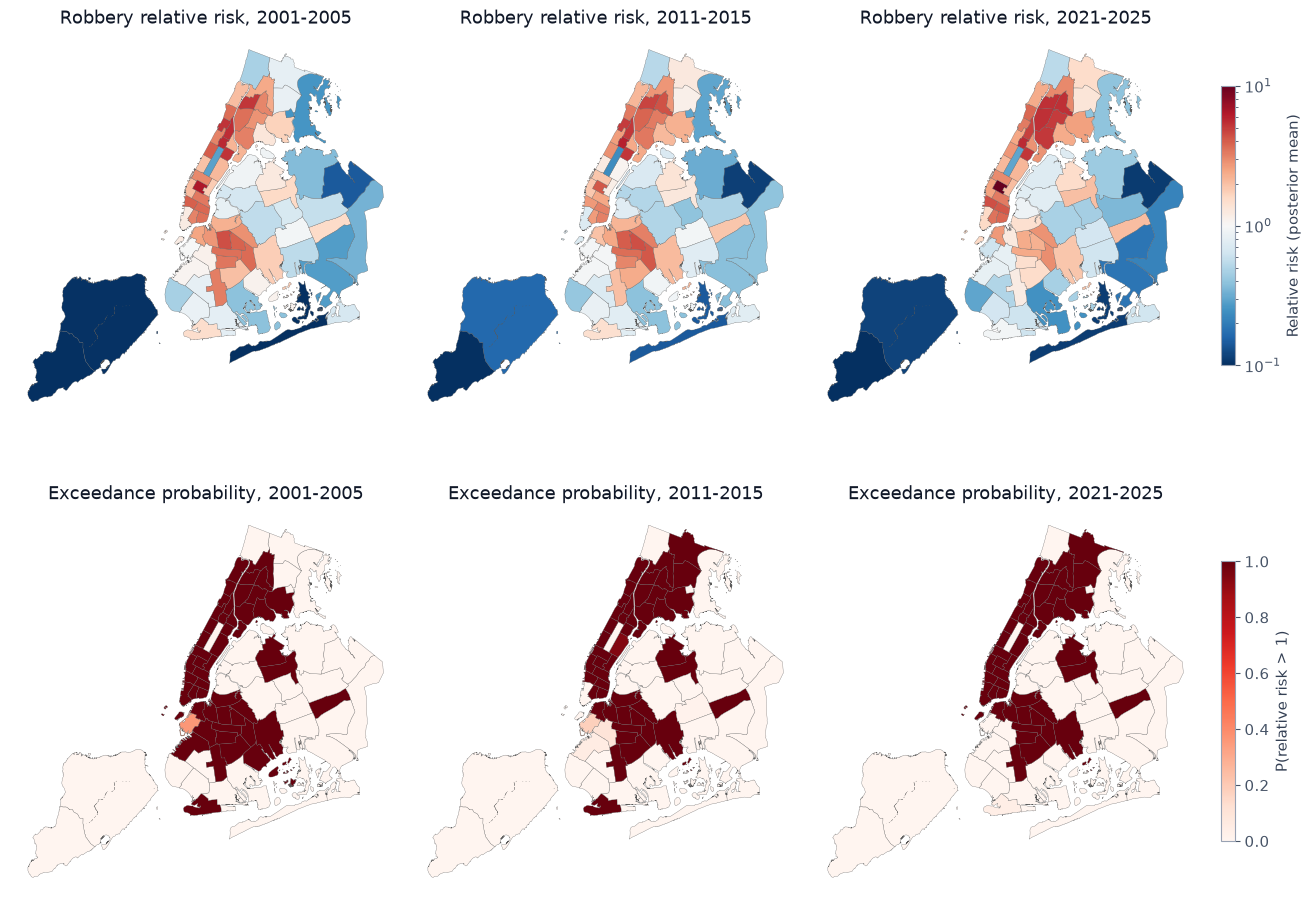

All chains converge (largest R-hat **1.001**). **42** units have P(RR > 1) above 0.95 in all three windows; **2** are above it in 2021-2025 but not in 2001-2005 (units 47, 49), and **4** the reverse (units 60, 69, 72, 78). Log relative risks in the first and last window correlate at **0.95**. Because each unit has hundreds to thousands of robberies per window, the posterior mean stays within **3.9%** of the raw ratio: smoothing changes little here, and the value of the model is the exceedance probability. About **37%** of the random-effect standard deviation is spatially structured.

In [16]:
area_h = geom_h["area_km2"].to_numpy(float)
rob = mat("robbery")
bym_fits, bym_rows = {}, []
for name, (a, b) in BYM_WINDOWS.items():
    cols_ = [k for k, yr in enumerate(years) if a <= yr <= b]
    O = rob[:, cols_].sum(axis=1)
    E = expected_counts(area_h, observed=O)
    fit = BYM(O, E, w_h, model="bym", backend="gibbs", seed=SEED)
    bym_fits[name] = fit
    bym_rows.append({
        "window": name, "robberies": O.sum(),
        "max R-hat": fit.max_rhat, "min ESS": fit.min_ess,
        "spatial fraction": float(np.mean(fit.spatial_fraction)),
        "RR min": fit.rr_mean.min(), "RR max": fit.rr_mean.max(),
        "units P(RR>1) > 0.95": int((fit.exceedance(1.0) > 0.95).sum()),
        "max |RR - SMR| / SMR": float(np.max(np.abs(fit.rr_mean - fit.smr) / np.where(fit.smr > 0, fit.smr, np.nan))),
    })
bym_tbl = pd.DataFrame(bym_rows).set_index("window")
display(bym_tbl.style.format({
    "robberies": "{:,.0f}", "max R-hat": "{:.3f}", "min ESS": "{:.0f}", "spatial fraction": "{:.2f}",
    "RR min": "{:.2f}", "RR max": "{:.2f}", "max |RR - SMR| / SMR": "{:.3f}",
}))

risk = geom_h[["geometry"]].copy()
for name, fit in bym_fits.items():
    risk[f"rr_{name}"] = fit.rr_mean
    risk[f"ex_{name}"] = fit.exceedance(1.0)

fig, axes = plt.subplots(2, 3, figsize=(13, 9.5), constrained_layout=True)
rr_norm = LogNorm(vmin=0.1, vmax=10)
for k, name in enumerate(BYM_WINDOWS):
    risk.plot(
        column=f"rr_{name}", cmap="RdBu_r", norm=rr_norm, edgecolor="0.35", linewidth=0.2,
        ax=axes[0, k], legend=(k == 2), legend_kwds={"shrink": 0.6, "label": "Relative risk (posterior mean)"},
    )
    axes[0, k].set_title(f"Robbery relative risk, {name}")
    axes[0, k].set_axis_off()
    risk.plot(
        column=f"ex_{name}", cmap="Reds", vmin=0, vmax=1, edgecolor="0.35", linewidth=0.2,
        ax=axes[1, k], legend=(k == 2), legend_kwds={"shrink": 0.6, "label": "P(relative risk > 1)"},
    )
    axes[1, k].set_title(f"Exceedance probability, {name}")
    axes[1, k].set_axis_off()
plt.show()

names_ = list(BYM_WINDOWS)
high = np.column_stack([bym_fits[n].exceedance(1.0) > 0.95 for n in names_])
always = high.all(axis=1)
gained = (~high[:, 0]) & high[:, -1]
lost = high[:, 0] & (~high[:, -1])
rr_corr = float(np.corrcoef(np.log(bym_fits[names_[0]].rr_mean), np.log(bym_fits[names_[-1]].rr_mean))[0, 1])
display(Markdown(
    f"All chains converge (largest R-hat **{bym_tbl['max R-hat'].max():.3f}**). "
    f"**{int(always.sum())}** units have P(RR > 1) above 0.95 in all three windows; "
    f"**{int(gained.sum())}** are above it in {names_[-1]} but not in {names_[0]}"
    + (f" (units {', '.join(str(units[j]) for j in np.where(gained)[0])})" if gained.any() else "")
    + f", and **{int(lost.sum())}** the reverse"
    + (f" (units {', '.join(str(units[j]) for j in np.where(lost)[0])})" if lost.any() else "")
    + f". Log relative risks in the first and last window correlate at **{rr_corr:.2f}**. "
    f"Because each unit has hundreds to thousands of robberies per window, the posterior mean stays within "
    f"**{bym_tbl['max |RR - SMR| / SMR'].max() * 100:.1f}%** of the raw ratio: smoothing changes little here, and the "
    f"value of the model is the exceedance probability. About **{bym_tbl['spatial fraction'].mean() * 100:.0f}%** of the "
    f"random-effect standard deviation is spatially structured."
))

## Validation: forward in time and blocked in space

The guideline warns against random train/test splits. Two designs are used on the harmonized panel.

- **Forward validation.** For each target year from 2016 to 2025 the model is fitted to all earlier years and predicts the target year from the previous year's values, so no future information is used.
- **Leave-one-borough-out.** The model is fitted without one borough and predicts that borough, which tests spatial transferability.

Four predictors are compared: last year's count (naive), the mean of the last three years, a pooled Poisson autoregression on the unit's own lag, and the same model with the neighbors' lagged mean added.

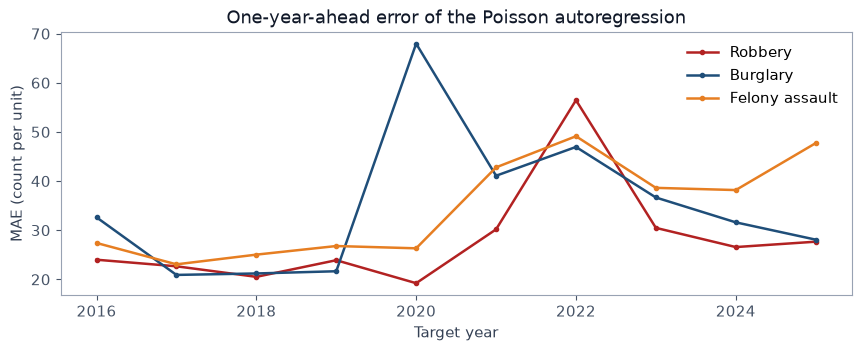

Lowest forward MAE: **Burglary**: Poisson AR (34.9, mean count 175); **Felony assault**: Naive (last year) (33.4, mean count 315); **Robbery**: Poisson AR (28.2, mean count 198). Adding the neighbors' lag changes forward MAE by **+0.3%** (Burglary), **+0.0%** (Felony assault), **+0.2%** (Robbery). The hardest target years are **2022** (Robbery), **2020** (Burglary), **2022** (Felony assault). Errors are in counts per unit and year.

In [17]:
def design(c, t_idx, spatial):
    # Rows for target-year indices t_idx: intercept, log own lag, optional log neighbor lag.
    y_ = RAW[c][:, t_idx].ravel(order="F")
    cols_ = [np.ones_like(y_), np.log1p(RAW[c][:, [t - 1 for t in t_idx]]).ravel(order="F")]
    if spatial:
        wl = np.column_stack([w_h.lag(RAW[c][:, t - 1]) for t in t_idx])
        cols_.append(np.log1p(wl).ravel(order="F"))
    return y_, np.column_stack(cols_)


def fit_predict(c, train_idx, test_idx, spatial, train_units=None, test_units=None):
    ytr, Xtr = design(c, train_idx, spatial)
    yte, Xte = design(c, test_idx, spatial)
    if train_units is not None:
        ytr, Xtr = ytr[np.tile(train_units, len(train_idx))], Xtr[np.tile(train_units, len(train_idx))]
        yte, Xte = yte[np.tile(test_units, len(test_idx))], Xte[np.tile(test_units, len(test_idx))]
    model = sm.GLM(ytr, Xtr, family=sm.families.Poisson()).fit()
    return yte, model.predict(Xte)


val_idx = [years.index(v) for v in VAL_YEARS]
boro_arr = geom_h["borough"].to_numpy()
val_rows, err_by_year = [], {}
for c, label in FOCUS_COUNTS.items():
    preds = {k: [] for k in ["Naive (last year)", "Mean of last 3 years", "Poisson AR", "Poisson AR + neighbors"]}
    truth = []
    for t in val_idx:
        truth.append(RAW[c][:, t])
        preds["Naive (last year)"].append(RAW[c][:, t - 1])
        preds["Mean of last 3 years"].append(RAW[c][:, t - 3:t].mean(axis=1))
        train = list(range(1, t))
        preds["Poisson AR"].append(fit_predict(c, train, [t], False)[1])
        preds["Poisson AR + neighbors"].append(fit_predict(c, train, [t], True)[1])
    truth = np.concatenate(truth)
    for k, p in preds.items():
        e = np.concatenate(p) - truth
        val_rows.append({"outcome": label, "model": k, "design": "forward", "MAE": np.abs(e).mean(),
                         "RMSE": np.sqrt((e ** 2).mean())})
    err_by_year[c] = np.abs(np.column_stack(preds["Poisson AR"]) - np.column_stack(
        [RAW[c][:, t] for t in val_idx])).mean(axis=0)

    all_idx = list(range(1, N_T))
    for spatial, k in [(False, "Poisson AR"), (True, "Poisson AR + neighbors")]:
        errs = []
        for b in BORO_COLORS:
            te = boro_arr == b
            yte, pte = fit_predict(c, all_idx, all_idx, spatial, train_units=~te, test_units=te)
            errs.append(pte - yte)
        e = np.concatenate(errs)
        val_rows.append({"outcome": label, "model": k, "design": "leave-one-borough-out",
                         "MAE": np.abs(e).mean(), "RMSE": np.sqrt((e ** 2).mean())})

val_tbl = pd.DataFrame(val_rows)
val_wide = val_tbl.pivot_table(index=["design", "model"], columns="outcome", values=["MAE", "RMSE"])
val_wide = val_wide.reindex(columns=list(FOCUS_COUNTS.values()), level=1)
display(val_wide.style.format("{:.1f}"))

fig, ax = plt.subplots(figsize=(8.5, 3.4), constrained_layout=True)
for c, label in FOCUS_COUNTS.items():
    ax.plot(VAL_YEARS, err_by_year[c], color=FOCUS_COLORS[c], lw=1.8, marker="o", ms=3, label=label)
ax.set_xlabel("Target year")
ax.set_ylabel("MAE (count per unit)")
ax.set_title("One-year-ahead error of the Poisson autoregression")
ax.legend(frameon=False)
plt.show()

fwd = val_tbl[val_tbl["design"] == "forward"].pivot(index="model", columns="outcome", values="MAE")
best = fwd.idxmin()
gain = 100 * (1 - fwd.loc["Poisson AR + neighbors"] / fwd.loc["Poisson AR"])
worst_year = {FOCUS_COUNTS[c]: VAL_YEARS[int(np.argmax(err_by_year[c]))] for c in FOCUS_COUNTS}
mean_level = {FOCUS_COUNTS[c]: float(RAW[c][:, val_idx].mean()) for c in FOCUS_COUNTS}
display(Markdown(
    "Lowest forward MAE: "
    + "; ".join(f"**{o}**: {best[o]} ({fwd.loc[best[o], o]:.1f}, mean count {mean_level[o]:.0f})" for o in fwd.columns)
    + ". Adding the neighbors' lag changes forward MAE by "
    + ", ".join(f"**{-gain[o]:+.1f}%** ({o})" for o in fwd.columns)
    + ". The hardest target years are "
    + ", ".join(f"**{y_}** ({o})" for o, y_ in worst_year.items())
    + ". Errors are in counts per unit and year."
))

## Leaflet emerging-hotspot map

Map the robbery emerging-hotspot categories (harmonized units) on OpenStreetMap for street context. The tooltip also reports the number of years each unit spent in a robbery hot spot.

In [18]:
emerge_map = emerge.reset_index()[["precinct", "category", "hot_years_robbery", "geometry"]].copy()
emerge_map["geometry"] = emerge_map.geometry.simplify(30, preserve_topology=True)
emerge_map = emerge_map.to_crs(4326)
emerge_map["hot_years_robbery"] = emerge_map["hot_years_robbery"].astype(int)
emerge_map["precinct"] = emerge_map["precinct"].astype(int)
center = [
    float((emerge_map.total_bounds[1] + emerge_map.total_bounds[3]) / 2),
    float((emerge_map.total_bounds[0] + emerge_map.total_bounds[2]) / 2),
]
m_emerge = folium.Map(
    location=center, zoom_start=10, tiles="OpenStreetMap", control_scale=True
)


def emerge_style(feature):
    lab = feature["properties"].get("category", "no pattern")
    return {
        "fillColor": palette.get(lab, "#cccccc"),
        "color": "#333333",
        "weight": 0.7,
        "fillOpacity": 0.78,
    }


folium.GeoJson(
    data=json.loads(emerge_map.to_json()),
    name="Emerging hotspots - robbery",
    style_function=emerge_style,
    tooltip=folium.GeoJsonTooltip(
        fields=["precinct", "category", "hot_years_robbery"],
        aliases=["Precinct", "Category", "Years in a hot spot"],
    ),
).add_to(m_emerge)
folium.LayerControl(collapsed=False).add_to(m_emerge)
display(Markdown("### Emerging hotspot categories - robbery (Leaflet + OSM)"))
display(m_emerge)


### Emerging hotspot categories - robbery (Leaflet + OSM)

## Decision log

| Decision | Choice | Why |
|---|---|---|
| Spatial unit | NYPD precinct | Matches Columbia / NYPD published tables |
| Harmonized geography | Precincts 120, 121, 122 merged (75 units) for full-period analyses | Precinct 121 opened in 2013; unmerged series are incomplete or refer to changing territories |
| Panel years | 2000-2025 | Full Excel span in the local database |
| Focus outcomes | Robbery, burglary, felony assault | Guideline Section 10 recommended design |
| Exposure | Precinct area (km$^2$) | Resident population not yet joined; area is a transparent proxy |
| Change window | 2019-2024 | Pre-pandemic baseline vs recent complete year |
| Weights | Queen contiguity | Natural for compact urban polygons; Moran's I checked with Rook and KNN-4 |
| Local inference | LISA uncorrected and FDR (9,999 permutations); Gi* analytic with FDR | 77 simultaneous local tests |
| Emerging hotspots | Gi* membership + Mann-Kendall, three outcomes | Part 9.3 / guideline Model 6 style |
| Count models | Poisson and NegBin with area offset; dispersion estimated | Crime is a count; NegBin handles overdispersion |
| Cross-section spatial models | OLS, spatial lag, spatial error on 2024 rates; LM tests | Tests neighboring-precinct dependence (H1) |
| Panel models | Two-way FE, FE count models, dynamic spatial lag (ML on demeaned data) | Guideline Models 1, 2, and 4 |
| Panel covariates | Lagged other major felonies and drug offenses | No socioeconomic data in the local database |
| Bayesian model | BYM by five-year window, built-in sampler | Guideline Model 5 without an extra dependency |
| Validation | One-year-ahead forward validation; leave-one-borough-out | Guideline Section 6: no random splits |
| Interactive basemap | OpenStreetMap via Folium/Leaflet | Street context for precinct patterns |

### Takeaways

1. **Distribution.** Rankings by count and by area rate are not identical - small dense precincts rise under rates.
2. **Autocorrelation (H1).** Moran's I is positive for robbery, burglary, assault, violent, and property in every year of the panel and significant in most outcome-years. The 2024 result holds under Queen, Rook, and KNN weights and for counts and rates.
3. **Different trends (H3, H4).** Robbery and burglary fell by more than half between 2000 and 2025, while felony assault ended above its 2000 level after a long rise from its 2008 low. The property composite fell more than the violent composite.
4. **Different geographies (H3).** After FDR adjustment, robbery and felony assault share a High-High cluster in the Bronx, and burglary has no High-High precinct in 2024.
5. **Hotspots persist for some offenses and shift for others (H2).** Felony assault has persistent and intensifying hot spots. Robbery hot spots are sporadic or diminishing, with no unit hot in 90% of the years. Burglary hot spots are mostly sporadic, with a few new ones.
6. **Models.** Counts are overdispersed, so the negative binomial is preferred to Poisson. In the 2024 cross-section, last year's rate explains nearly all of the variation and no spatial dependence is left in the residuals. In the panel, after unit and year effects, crime is persistent over time and still moves with neighboring units in the same year, most strongly for felony assault.
7. **Bayesian risk maps.** Most high-intensity units stay high in all three five-year windows. Counts are large, so smoothing barely changes the estimates; the exceedance probabilities are the useful output.
8. **Validation.** Last year's count is a strong benchmark. The pooled Poisson autoregression improves on it only slightly for robbery and burglary and not for felony assault, the neighbors' lag adds nothing to one-year-ahead accuracy, and errors peak in 2020 and 2022.

### Extensions (from *crime analysis.qmd*)

- Join Census ACS population and socioeconomic variables, land use, and transit to the precinct panel, and compare resident-population rates with daytime-exposure rates.
- Build a precinct-month panel from NYPD incident-level complaint data for seasonal decomposition, day-of-week patterns, and a space-time cube.
- Fit a single Bayesian space-time model (BYM2 with temporal random effects and a space-time interaction) with the PyMC backend, and compare models by WAIC or LOO.
- Use bias-corrected estimators for the dynamic spatial panel.

### Methodological caution

Reported crime is shaped by reporting behavior, enforcement intensity, and classification practices. Drug offenses in particular record enforcement activity. Precinct-level associations are geographic, not individual causal effects, and should not by themselves justify enforcement decisions.